# Inti, asistente del Consultorio Integra Salud
## Segundo avance de proyecto: primera versión multimodal con PLN y visión por computadora


Este cuaderno amplía el chatbot de reglas del Avance 1 con tres componentes nuevos:

1. Un **clasificador de intenciones** entrenado con un conjunto de datos textual propio (preprocesamiento con NLTK y spaCy, TF-IDF o Bag of Words, Naive Bayes o SVM).
2. Un **clasificador visual de tipo de documento** basado en EfficientNet-B0 con transferencia de aprendizaje, que distingue identificación, receta previa, estudio de laboratorio y otras imágenes.
3. Una **integración multimodal**: Inti recibe texto o imágenes, aplica primero sus filtros de seguridad y comunica en la conversación el resultado del clasificador visual.

**Aviso:** todos los datos del consultorio, las frases de entrenamiento y los documentos sintéticos son ficticios y se usan solo con fines académicos. Inti identifica el tipo de documento, pero no lee ni interpreta su contenido, no diagnostica y no recomienda tratamientos.

**Cómo ejecutarlo:** en Google Colab elija Entorno de ejecución, Cambiar tipo de entorno, GPU T4 (opcional pero recomendado) y después Ejecutar todas. Con CPU el cuaderno completo tarda alrededor de 15 minutos.

## 0. Instalación e importaciones

In [1]:
# Dependencias que Colab no trae instaladas
!pip install -q efficientnet_pytorch
!python -m spacy download es_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')


In [2]:
import os, re, sys, time, random, unicodedata, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk, spacy
from nltk.tokenize import RegexpTokenizer
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from sklearn.metrics.pairwise import cosine_similarity

import torch, torch.nn as nn
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from efficientnet_pytorch import EfficientNet

warnings.filterwarnings("ignore")
nltk.download("stopwords", quiet=True)

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)
for carpeta in ["datos", "figuras", "pruebas", "modelos"]:
    os.makedirs(carpeta, exist_ok=True)

assert sys.version_info >= (3, 10), "Se requiere Python 3.10 o superior"
print("Python", sys.version.split()[0], "| NLTK", nltk.__version__, "| spaCy", spacy.__version__,
      "| PyTorch", torch.__version__, "| dispositivo:", DISPOSITIVO)

Python 3.13.18 | NLTK 3.10.4 | spaCy 3.8.18 | PyTorch 2.15.0+cu132 | dispositivo: cpu


## 1. Recuperación del Avance 1

Se conservan sin cambios la base de conocimiento, los filtros de seguridad, la extracción de entidades y la gestión del agendamiento del Avance 1. El clasificador de esta entrega reemplaza **solo** la capa 4 (clasificación por raíces). Los filtros de emergencia, encuadre clínico y contención siguen siendo reglas y se evalúan antes que cualquier modelo, porque en ellos un falso negativo es el error más costoso del sistema.

In [3]:
# 1.1 Base de conocimiento (Avance 1)
# Datos ficticios del consultorio (solo para fines académicos)
CONSULTORIO = {
    "nombre": "Consultorio Integra Salud",
    "asistente": "Inti",
    "telefono": "55 0000 0000",
    "correo": "contacto@integrasalud.example",
    "direccion": "Av. Ejemplo 123, colonia Centro, Ciudad de México",
}

# Horario de atención: (hora de apertura, hora de cierre); None = cerrado
HORARIO = {
    "lunes": (10, 18), "martes": (10, 18), "miercoles": (10, 18),
    "jueves": (10, 18), "viernes": (10, 18), "sabado": (10, 14),
    "domingo": None,
}
NOMBRE_DIA = {"lunes": "lunes", "martes": "martes", "miercoles": "miércoles",
              "jueves": "jueves", "viernes": "viernes", "sabado": "sábado",
              "domingo": "domingo"}

# Catálogo de servicios con costos de prueba (pesos mexicanos)
SERVICIOS = {
    "medicina_general_primera":     {"nombre": "Consulta de medicina general, primera vez", "modalidad": "medicina_general", "duracion": 45, "costo": 800},
    "medicina_general_subsecuente": {"nombre": "Consulta de medicina general, seguimiento",  "modalidad": "medicina_general", "duracion": 30, "costo": 600},
    "homeopatia_primera":           {"nombre": "Consulta de homeopatía, primera vez",         "modalidad": "homeopatia",       "duracion": 60, "costo": 1000},
    "homeopatia_subsecuente":       {"nombre": "Consulta de homeopatía, seguimiento",          "modalidad": "homeopatia",       "duracion": 45, "costo": 700},
    "certificado_medico":           {"nombre": "Expedición de certificado médico",             "modalidad": "certificado",      "duracion": 30, "costo": 500},
}

METODOS_PAGO = ["efectivo", "tarjeta de débito o crédito en el consultorio", "transferencia electrónica"]

DOCUMENTOS = ["una identificación oficial",
              "la lista de medicamentos que toma actualmente"]
DOCUMENTOS_OPCIONALES = "Si tiene estudios, análisis o recetas previas, llévelos también."

# Agenda simulada: bloques de una hora; se marcan algunos como ocupados
def construir_agenda_base():
    agenda = {}
    for dia, horario in HORARIO.items():
        if horario:
            apertura, cierre = horario
            agenda[dia] = list(range(apertura, cierre))  # el último bloque inicia una hora antes del cierre
    for dia, hora in [("lunes", 10), ("martes", 12), ("jueves", 16), ("sabado", 10)]:
        agenda[dia].remove(hora)  # bloques ocupados de prueba
    return agenda

print(construir_agenda_base())

{'lunes': [11, 12, 13, 14, 15, 16, 17], 'martes': [10, 11, 13, 14, 15, 16, 17], 'miercoles': [10, 11, 12, 13, 14, 15, 16, 17], 'jueves': [10, 11, 12, 13, 14, 15, 17], 'viernes': [10, 11, 12, 13, 14, 15, 16, 17], 'sabado': [11, 12, 13]}


In [4]:
def formatear_lista(elementos):
    # Une una lista en español: "a, b y c"
    if len(elementos) == 1:
        return elementos[0]
    return ", ".join(elementos[:-1]) + " y " + elementos[-1]

def texto_costos(modalidad=None):
    lineas = [f"{s['nombre']}: ${s['costo']:,} MXN ({s['duracion']} minutos)"
              for s in SERVICIOS.values() if modalidad in (None, s["modalidad"])]
    return " ".join(f"{linea}." for linea in lineas)

def texto_horario():
    return ("Lunes a viernes: 10:00 a 18:00 horas. Sábado: 10:00 a 14:00 horas. "
            "Domingo: cerrado.")

DATOS_CONTACTO = (f"teléfono {CONSULTORIO['telefono']} o correo {CONSULTORIO['correo']}, "
                  "de lunes a viernes de 10:00 a 18:00 horas y sábados de 10:00 a 14:00 horas")

# Respuestas de la base de conocimiento, organizadas por clave
RESPUESTAS = {
    "saludo": (
        "Hola, soy Inti, asistente automatizada del Consultorio Integra Salud. "
        "Puedo darle información del consultorio (horarios, ubicación, contacto, servicios, costos, "
        "formas de pago y documentos), orientarle sobre la consulta de homeopatía, registrar una cita "
        "de prueba, consultar una cita registrada o comunicarle con una persona. No puedo dar "
        "orientación médica. Esta es una versión de prueba con datos ficticios: por favor no comparta "
        "datos personales ni de salud. ¿En qué le puedo ayudar?"),
    "info_horarios": f"Nuestro horario es el siguiente. {texto_horario()} ¿Le gustaría agendar una cita?",
    "info_ubicacion": f"Estamos en {CONSULTORIO['direccion']} (dirección ficticia de prueba). ¿Necesita algo más?",
    "info_contacto": f"Puede comunicarse al {DATOS_CONTACTO}. ¿Le ayudo con algo más?",
    "info_servicios": (
        "Ofrecemos consulta de medicina general, consulta de homeopatía (primera vez y seguimiento) "
        "y expedición de certificado médico. Si quiere, le comparto los costos o le explico en qué "
        "consiste la consulta de homeopatía."),
    "info_costos": "Estos son los costos de prueba: {detalle} ¿Desea agendar una cita?",
    "info_metodos_pago": f"Aceptamos {formatear_lista(METODOS_PAGO)}. ¿Le ayudo con algo más?",
    "info_documentos": (f"Para su consulta le recomendamos llevar {formatear_lista(DOCUMENTOS)}. "
                        f"{DOCUMENTOS_OPCIONALES} Le pedimos llegar quince minutos antes para su registro."),
    "info_menu": (
        "Con gusto. Puedo informarle sobre horarios, ubicación, contacto, servicios, costos, "
        "formas de pago o documentos para la consulta. ¿Sobre cuál tema desea saber?"),
    "orientacion_homeopatia": (
        "La consulta de homeopatía es una valoración que realiza el médico del consultorio; la primera "
        "visita dura aproximadamente sesenta minutos e incluye una entrevista detallada sobre sus "
        "antecedentes y hábitos. Es una modalidad complementaria a la medicina general y la decisión "
        "sobre su pertinencia corresponde al profesional. ¿Le gustaría agendar una consulta o conocer los costos?"),
    "agendar_faltan": (
        "Para registrar su cita de prueba necesito {faltantes}. Escríbalo en un solo mensaje, por ejemplo: "
        "\"homeopatía primera vez el jueves a las 11\". Agendamos de lunes a viernes de 10:00 a 17:00 "
        "y sábados de 10:00 a 13:00."),
    "agendar_cerrado": "El consultorio no atiende en {dia}. Puede elegir de lunes a sábado. ¿Qué otro día le acomoda?",
    "agendar_no_disponible": (
        "El {dia} a las {hora} no hay espacio disponible. Los horarios libres ese día son: {libres}. "
        "Escriba de nuevo el servicio, el día y la hora que prefiera."),
    "agendar_exito": (
        "Su cita de prueba quedó registrada. Servicio: {servicio}. Día: {dia}. Hora: {hora}. "
        "Identificador: {id_cita}. {nota}Le pedimos llegar quince minutos antes y llevar una "
        "identificación oficial. Guarde su identificador para consultar la cita. ¿Le ayudo con algo más?"),
    "consultar_pide_id": "Con gusto la reviso. ¿Me comparte el identificador de su cita? Tiene el formato IS101.",
    "consultar_exito": (
        "Encontré su cita {id_cita}. Servicio: {servicio}. Día: {dia}. Hora: {hora}. En esta versión no es "
        "posible cancelar ni reagendar por este medio; para hacerlo comuníquese al consultorio."),
    "consultar_no_encontrada": (
        "No encontré una cita con el identificador {id_cita} en esta sesión. Puedo registrar una cita nueva "
        "o comunicarle con una persona del consultorio. ¿Qué prefiere?"),
    "derivar_humano": (
        "Entiendo, prefiere atención personal. Puede comunicarse al {contacto}. Tenga a la mano su nombre "
        "y, si ya tiene cita, su identificador."),
    "derivar_fuera_alcance": (
        "La cancelación y el reagendamiento de citas todavía no están disponibles en este asistente. "
        "Para hacerlo comuníquese al {contacto}."),
    "emergencia": (
        "Lo que describe puede requerir atención inmediata. Por favor llame ahora al 911 o acuda al servicio "
        "de urgencias más cercano. Si usted o alguien más está en riesgo de hacerse daño, también puede "
        "llamar a la Línea de la Vida al 800 911 2000, disponible las 24 horas. No espere a su próxima cita."),
    "encuadre_clinico": (
        "Como asistente automatizada no puedo valorar síntomas ni recomendar medicamentos o tratamientos; eso "
        "corresponde al médico. Puedo ayudarle a registrar una consulta. Si los síntomas son intensos, empeoran "
        "rápidamente o le preocupan, acuda a urgencias o llame al 911."),
    "contencion_1": (
        "Entiendo que esta situación es incómoda y lamento la molestia. Estoy aquí para ayudarle. ¿Quiere que "
        "lo intentemos de otra forma o prefiere que le comunique con una persona del consultorio?"),
    "contencion_2": (
        "Lamento mucho que la experiencia no haya sido la que esperaba. Para resolverlo mejor, puede comunicarse "
        "con una persona del consultorio al {contacto}."),
    "contencion_3": (
        "Entiendo su molestia y quiero que reciba la mejor atención. Por favor comuníquese al teléfono "
        "{telefono}. Aquí estaré si desea retomar la conversación más tarde."),
    "fallback": (
        "No estoy segura de haber entendido. Puedo ayudarle con información del consultorio, orientación sobre "
        "homeopatía, agendar una cita, consultar una cita registrada o comunicarle con una persona. "
        "¿Qué le gustaría hacer?"),
    "fallback_derivacion": (
        "Sigo sin entender su mensaje y no quiero hacerle perder tiempo. Puede escribirme de otra forma o "
        "comunicarse con una persona del consultorio al {contacto}."),
    "despedida": ("Gracias por escribir al Consultorio Integra Salud. Si necesita algo más, aquí estaré. "
                  "Que tenga un buen día."),
    "entrada_vacia": "No recibí ningún texto. Escriba su pregunta, por ejemplo: \"¿cuál es su horario?\"",
}
print(len(RESPUESTAS), "respuestas cargadas")

28 respuestas cargadas


In [5]:
# 1.2 Catálogo de intenciones y palabras clave por tema (Avance 1, usado por la capa de reglas y por la entidad tema)
INTENCIONES = {
    "saludo": [
        "hola", "buenos dias", "buenas tardes", "buenas noches", "que tal",
        "hola inti", "me podria apoyar", "necesito ayuda",
    ],
    "consultar_informacion": [
        "cual es el horario", "horario de atencion", "a que hora abren", "a que hora cierran",
        "trabajan los sabados", "abren el domingo", "cuando atienden",
        "donde estan ubicados", "cual es la direccion", "como llego al consultorio",
        "cual es su telefono", "como los contacto", "tienen correo",
        "que servicios ofrecen", "que especialidades tienen",
        "cuanto cuesta la consulta", "cual es el precio", "costo de la consulta",
        "aceptan tarjeta", "formas de pago", "puedo pagar con transferencia",
        "que documentos debo llevar", "requisitos para la consulta",
    ],
    "orientacion_homeopatia": [
        "que es la homeopatia", "en que consiste la consulta de homeopatia",
        "como es la primera consulta homeopatica", "como funciona la homeopatia",
        "diferencia entre homeopatia y alopatia", "el doctor es homeopata",
    ],
    "agendar_cita": [
        "quiero agendar una cita", "agendar cita", "agendame una cita",
        "me gustaria reservar una consulta", "como pido una cita", "quiero sacar una cita",
        "apartar una cita", "programar una cita",
    ],
    "consultar_cita": [
        "quiero ver mi cita", "consultar mi cita", "cuando es mi cita", "revisa mi cita",
        "ya tengo cita", "datos de mi cita", "a que hora es mi cita", "estado de mi cita",
    ],
    "derivar_humano": [
        "quiero hablar con una persona", "necesito atencion humana", "pasame con recepcion",
        "comunicame con alguien", "prefiero hablar con alguien", "no quiero hablar con un bot",
        "hablar con un asesor", "quiero cancelar mi cita", "necesito reagendar mi cita",
        "cambiar mi cita",
    ],
    "despedida": [
        "gracias", "muchas gracias", "hasta luego", "adios", "nos vemos", "eso es todo", "bye",
    ],
}

# Desempate: si dos intenciones obtienen el mismo puntaje, gana la que aparece primero
PRIORIDAD = ["derivar_humano", "consultar_cita", "agendar_cita", "orientacion_homeopatia",
             "consultar_informacion", "despedida", "saludo"]
UMBRAL = 1  # mínimo de raíces de contenido compartidas para aceptar una intención

# Palabras clave por tema de la intención consultar_informacion
TEMAS = {
    "metodos_pago": ["tarjeta", "efectivo", "transferencia", "pago", "pagar", "credito", "debito", "aceptan"],
    "costos":       ["cuesta", "costo", "precio", "cuanto", "tarifa", "cobran"],
    "documentos":   ["documentos", "llevar", "requisitos", "identificacion", "estudios", "papeles"],
    "horarios":     ["horario", "hora", "abren", "cierran", "abierto", "sabado", "domingo", "atienden", "trabajan"],
    "ubicacion":    ["direccion", "ubicados", "ubicacion", "donde", "llego", "llegar", "encuentran", "mapa"],
    "contacto":     ["telefono", "correo", "contacto", "contacto", "contactar", "llamar", "numero", "whatsapp", "email"],
    "servicios":    ["servicios", "ofrecen", "especialidades", "especialidad"],
}

In [6]:
# 1.3 Filtros de seguridad (Avance 1)
# Filtros de seguridad: patrones sobre el texto normalizado (sin acentos, minúsculas)
PATRONES_EMERGENCIA = [
    r"\b(dolor|duele|presion|opresion)\b.{0,30}\bpecho\b",
    r"\bno puedo respirar\b", r"\bme falta el aire\b", r"\bme ahogo\b", r"\bdificultad para respirar\b",
    r"\bsangrando\b", r"\bhemorragia\b",
    r"\bdesmay\w*", r"\bperdi el conocimiento\b", r"\binconsciente\b", r"\bconvulsi\w*",
    r"\binfarto\b", r"\bderrame cerebral\b", r"\bembolia\b", r"\bparalisis\b",
    r"\bme siento muy mal\b", r"\bsiento que me muero\b", r"\bme voy a morir\b", r"\bme estoy muriendo\b",
    r"\bhacerme dano\b", r"\blastimarme\b", r"\bsuicid\w*", r"\bquitarme la vida\b",
    r"\bno quiero vivir\b", r"\bmatarme\b",
    r"\bsobredosis\b", r"\benvenen\w*", r"\bintoxica\w*",
    r"\bemergencia\b", r"\burgencias?\b", r"\burgente\b",
]

# Regla secundaria: síntomas o solicitudes clínicas no urgentes
PATRONES_ENCUADRE = [
    r"\b(fiebre|tos|gripa|gripe|diarrea|vomit\w*|nausea\w*|mareo\w*|sintoma\w*|infeccion|alergia|comezon|dolor|duele\w*|inflamad\w*)\b",
    r"\bme siento mal\b",
    r"\b(que|cual) (medicamento|medicina|remedio|pastilla|tratamiento)\b",
    r"\bque (me|le|puedo|debo) (tomo|tomar|doy|dar)\b",
    r"\bdosis\b", r"\bdiagnostic\w*", r"\bme receta\w*", r"\bes grave\b",
]

# Diccionario reducido para el filtro de contención, organizado por familia
LEXICO_CONTENCION = {
    "lenguaje_agresivo": [
        "idiota", "estupido", "estupida", "imbecil", "tarado", "tarada", "menso", "mensa",
        "pendejo", "pendeja", "maldito", "maldita", "inutil", "porqueria", "basura",
    ],
    "enojo_frustracion": [
        "estoy harto", "estoy harta", "me tienes harto", "me tienes harta", "mala atencion",
        "pesimo servicio", "pesima atencion", "no sirve", "no sirves", "pierdo mi tiempo",
        "perdiendo mi tiempo", "no entiendes nada", "que fastidio", "que coraje",
        "estoy molesto", "estoy molesta", "estoy enojado", "estoy enojada",
    ],
    "impaciencia_usabilidad": [
        "llevo mucho esperando", "nadie responde", "nadie contesta", "siempre lo mismo",
        "otra vez el bot", "ya me canse", "tercera vez",
    ],
}

# Regla de alcance: cancelación o reagendamiento se derivan a una persona
PATRON_FUERA_ALCANCE = r"\b(cancel\w*|reagend\w*|cambiar mi cita|mover mi cita)\b"

In [7]:
# 1.4 Preprocesamiento del Avance 1 y vocabulario de raíces
tokenizer = RegexpTokenizer(r"\w+")   # separa en palabras alfanuméricas
stemmer = SnowballStemmer("spanish")   # reduce cada palabra a su raíz

def quitar_acentos(texto):
    texto = unicodedata.normalize("NFD", texto)
    return texto.encode("ascii", "ignore").decode("utf-8")

def normalizar_texto(texto):
    # Minúsculas, sin acentos, sin signos de puntuación y con espacios simples
    texto = quitar_acentos(texto.lower())
    texto = re.sub(r"[^a-z0-9\s]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

CONSERVAR = {"cuando", "donde", "todo"}
AGREGAR = {"quiero", "quisiera", "gustaria", "necesito", "favor", "podria", "puedo", "puede",
           "pueden", "saber", "usted", "ustedes", "inti", "consultorio", "debo"}
STOPWORDS = ({normalizar_texto(p) for p in stopwords.words("spanish")} - CONSERVAR) | AGREGAR

def preprocesar(texto):
    # Devuelve los tokens, las palabras de contenido y sus raíces
    tokens = tokenizer.tokenize(normalizar_texto(texto))
    contenido = [t for t in tokens if t not in STOPWORDS]
    raices = [stemmer.stem(t) for t in contenido]
    return {"tokens": tokens, "contenido": contenido, "raices": raices}

ejemplo = preprocesar("¡Hola! ¿Cuándo es mi cita de Homeopatía?")
for clave, valor in ejemplo.items():
    print(f"{clave:10s} {valor}")

tokens     ['hola', 'cuando', 'es', 'mi', 'cita', 'de', 'homeopatia']
contenido  ['hola', 'cuando', 'cita', 'homeopatia']
raices     ['hol', 'cuand', 'cit', 'homeopati']


In [8]:
# Vocabulario de raíces por intención: se construye a partir de los ejemplos del catálogo
def construir_vocabulario(intenciones):
    return {nombre: {r for frase in frases for r in preprocesar(frase)["raices"]}
            for nombre, frases in intenciones.items()}

VOCABULARIO = construir_vocabulario(INTENCIONES)
# Las palabras clave de los temas también identifican la intención consultar_informacion
RAICES_TEMA = {tema: {stemmer.stem(normalizar_texto(p)) for p in palabras} for tema, palabras in TEMAS.items()}
VOCABULARIO["consultar_informacion"] |= set().union(*RAICES_TEMA.values())

for intencion in PRIORIDAD:
    print(f"{intencion:23s} {sorted(VOCABULARIO[intencion])}")

derivar_humano          ['algui', 'asesor', 'atencion', 'bot', 'cambi', 'cancel', 'cit', 'comunicam', 'habl', 'human', 'pasam', 'person', 'prefier', 'reagend', 'recepcion']
consultar_cita          ['cit', 'consult', 'cuand', 'dat', 'hor', 'revis', 'ver']
agendar_cita            ['agend', 'agendam', 'apart', 'cit', 'consult', 'pid', 'program', 'reserv', 'sac']
orientacion_homeopatia  ['alopati', 'cons', 'consult', 'diferent', 'doctor', 'funcion', 'homeopat', 'homeopati', 'primer']
consultar_informacion   ['abiert', 'abren', 'acept', 'atencion', 'atiend', 'cierr', 'cobr', 'consult', 'contact', 'corre', 'cost', 'credit', 'cuand', 'cuant', 'cuest', 'debit', 'direccion', 'document', 'doming', 'dond', 'efect', 'email', 'encuentr', 'especial', 'estudi', 'form', 'hor', 'horari', 'identif', 'llam', 'lleg', 'llev', 'map', 'numer', 'ofrec', 'pag', 'papel', 'preci', 'requisit', 'sab', 'servici', 'tarif', 'tarjet', 'telefon', 'trabaj', 'transferent', 'ubic', 'whatsapp']
despedida               ['ad

In [9]:
# 1.5 Extracción de entidades (Avance 1)
DIAS = ["lunes", "martes", "miercoles", "jueves", "viernes", "sabado", "domingo"]
PATRON_HORA = re.compile(
    r"\b(?:a las|a la|las)\s+(\d{1,2})(?::(\d{2}))?\b"   # a las 11, a las 4:00
    r"|\b(\d{1,2}):(\d{2})\b"                             # 16:00
    r"|\b(\d{1,2})\s*(am|pm|a m|p m|hrs|horas|h)\b"      # 4 pm, 11 hrs
)
PATRON_ID = re.compile(r"\bis\s?(\d{3})\b")

def texto_para_entidades(texto):
    # Igual que normalizar_texto, pero conserva los dos puntos de las horas
    texto = quitar_acentos(texto.lower())
    texto = re.sub(r"[^a-z0-9:\s]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

def extraer_hora(texto):
    m = PATRON_HORA.search(texto)
    if not m:
        return None
    hora = int(m.group(1) or m.group(3) or m.group(5))
    minutos = int(m.group(2) or m.group(4) or 0)
    sufijo = (m.group(6) or "").replace(" ", "")
    if (sufijo == "pm" or "de la tarde" in texto) and hora < 12:
        hora += 12
    elif sufijo != "am" and 1 <= hora <= 7:
        hora += 12  # en el horario del consultorio, de 1 a 7 se interpreta como tarde
    if hora > 23 or minutos > 59:
        return None
    return (hora, minutos)

def extraer_servicio(texto):
    # Devuelve (clave del servicio, si el tipo se asumió por omisión)
    seguimiento = re.search(r"\b(seguimiento|subsecuente|control|segunda vez|segunda consulta)\b", texto)
    if re.search(r"\bcertificado", texto):
        return "certificado_medico", False
    if re.search(r"\bhomeopat", texto):
        modalidad = "homeopatia"
    elif re.search(r"\b(medicina general|medico general|consulta general|medicina)\b", texto):
        modalidad = "medicina_general"
    else:
        return None, False
    if seguimiento:
        return f"{modalidad}_subsecuente", False
    explicito = re.search(r"\bprimera\b", texto) is not None
    return f"{modalidad}_primera", not explicito

def extraer_tema(raices):
    puntajes = {tema: len(set(raices) & r) for tema, r in RAICES_TEMA.items()}
    mejor = max(puntajes, key=puntajes.get)  # empate: gana el primero del diccionario
    return mejor if puntajes[mejor] > 0 else None

def extraer_entidades(texto, raices):
    t = texto_para_entidades(texto)
    servicio, tipo_asumido = extraer_servicio(t)
    dia = next((d for d in DIAS if re.search(rf"\b{d}\b", t)), None)
    id_match = PATRON_ID.search(t)
    entidades = {
        "tema": extraer_tema(raices),
        "servicio": servicio,
        "tipo_asumido": tipo_asumido,
        "dia": dia,
        "hora": extraer_hora(t),
        "id_cita": f"IS{id_match.group(1)}" if id_match else None,
    }
    return {k: v for k, v in entidades.items() if v not in (None, False)}

for frase in ["Quiero homeopatía el sábado a las 11", "¿cuánto cuesta el certificado?",
              "mi cita es la IS101", "medicina general de seguimiento el viernes 4 pm"]:
    print(f"{frase:50s} -> {extraer_entidades(frase, preprocesar(frase)['raices'])}")

Quiero homeopatía el sábado a las 11               -> {'tema': 'horarios', 'servicio': 'homeopatia_primera', 'tipo_asumido': True, 'dia': 'sabado', 'hora': (11, 0)}
¿cuánto cuesta el certificado?                     -> {'tema': 'costos', 'servicio': 'certificado_medico'}
mi cita es la IS101                                -> {'id_cita': 'IS101'}
medicina general de seguimiento el viernes 4 pm    -> {'servicio': 'medicina_general_subsecuente', 'dia': 'viernes', 'hora': (16, 0)}


In [10]:
# 1.6 Identificación por reglas del Avance 1 (se conserva para comparar contra el modelo)
def coincide(patrones, texto):
    return any(re.search(p, texto) for p in patrones)

def detectar_contencion(texto):
    for familia, terminos in LEXICO_CONTENCION.items():
        if any(re.search(rf"\b{re.escape(t)}\b", texto) for t in terminos):
            return familia
    return None

def clasificar_por_raices(raices):
    conjunto = set(raices)
    puntajes = {i: len(conjunto & VOCABULARIO[i]) for i in PRIORIDAD}
    mejor = max(PRIORIDAD, key=lambda i: puntajes[i])  # max conserva el primero en caso de empate
    if puntajes[mejor] < UMBRAL:
        return "fallback", puntajes
    return mejor, puntajes

def identificar_intencion(texto, sesion):
    norm = normalizar_texto(texto)
    if not norm:
        return {"intencion": "entrada_vacia", "regla": "validacion_entrada", "entidades": {}, "puntajes": {}}

    # Capa 1: filtro de emergencia y encuadre clínico
    if coincide(PATRONES_EMERGENCIA, norm):
        return {"intencion": "emergencia", "regla": "filtro_emergencia", "entidades": {}, "puntajes": {}}
    if coincide(PATRONES_ENCUADRE, norm):
        return {"intencion": "encuadre_clinico", "regla": "filtro_emergencia_encuadre", "entidades": {}, "puntajes": {}}

    # Capa 2: filtro de contención
    familia = detectar_contencion(norm)
    if familia:
        return {"intencion": "contener_frustracion", "regla": f"filtro_contencion:{familia}",
                "entidades": {}, "puntajes": {}}

    pre = preprocesar(texto)
    ent = extraer_entidades(texto, pre["raices"])

    # Capa 3: reglas de contexto
    if "id_cita" in ent:
        return {"intencion": "consultar_cita", "regla": "contexto_id_cita", "entidades": ent, "puntajes": {}}
    datos_cita = any(k in ent for k in ("servicio", "dia", "hora"))
    if sesion["pendiente"] == "agendar_cita" and datos_cita:
        return {"intencion": "agendar_cita", "regla": "contexto_pendiente", "entidades": ent, "puntajes": {}}
    if all(k in ent for k in ("servicio", "dia", "hora")):
        return {"intencion": "agendar_cita", "regla": "entidades_completas", "entidades": ent, "puntajes": {}}

    # Capa 4: clasificación por raíces con umbral
    intencion, puntajes = clasificar_por_raices(pre["raices"])
    regla = "raices" if intencion != "fallback" else "umbral_no_alcanzado"
    return {"intencion": intencion, "regla": regla, "entidades": ent, "puntajes": puntajes}

print(identificar_intencion("¿A qué hora abren?", {"pendiente": None}))

{'intencion': 'consultar_informacion', 'regla': 'raices', 'entidades': {'tema': 'horarios'}, 'puntajes': {'derivar_humano': 0, 'consultar_cita': 1, 'agendar_cita': 0, 'orientacion_homeopatia': 0, 'consultar_informacion': 2, 'despedida': 0, 'saludo': 0}}


In [11]:
# 1.7 Gestión de la sesión y del agendamiento (Avance 1)
def crear_sesion():
    return {
        "agenda": construir_agenda_base(),
        "citas": {},
        "siguiente_id": 101,
        "contador_frustracion": 0,
        "fallbacks_consecutivos": 0,
        "pendiente": None,
        "historial": [],
    }

def formato_hora(hora):
    return f"{hora[0]:02d}:{hora[1]:02d}"

def gestionar_agendamiento(ent, sesion):
    faltantes = [nombre for clave, nombre in [("servicio", "el servicio"), ("dia", "el día"), ("hora", "la hora")]
                 if clave not in ent]
    if faltantes:
        sesion["pendiente"] = "agendar_cita"
        return RESPUESTAS["agendar_faltan"].format(faltantes=formatear_lista(faltantes))

    dia, hora = ent["dia"], ent["hora"]
    if dia not in sesion["agenda"]:
        sesion["pendiente"] = "agendar_cita"
        return RESPUESTAS["agendar_cerrado"].format(dia=NOMBRE_DIA[dia])

    libres = sesion["agenda"][dia]
    if hora[1] != 0 or hora[0] not in libres:
        sesion["pendiente"] = "agendar_cita"
        texto_libres = formatear_lista([f"{h:02d}:00" for h in libres]) if libres else "ninguno"
        return RESPUESTAS["agendar_no_disponible"].format(dia=NOMBRE_DIA[dia], hora=formato_hora(hora),
                                                          libres=texto_libres)

    # Registro de la cita: se ocupa el bloque y se genera el identificador
    id_cita = f"IS{sesion['siguiente_id']}"
    sesion["siguiente_id"] += 1
    libres.remove(hora[0])
    servicio = SERVICIOS[ent["servicio"]]["nombre"]
    sesion["citas"][id_cita] = {"servicio": servicio, "dia": NOMBRE_DIA[dia], "hora": formato_hora(hora)}
    sesion["pendiente"] = None
    sesion["contador_frustracion"] = 0  # un flujo completado reinicia el contador
    nota = ("La registré como primera vez; si es de seguimiento, indíquelo al llegar. "
            if ent.get("tipo_asumido") else "")
    return RESPUESTAS["agendar_exito"].format(servicio=servicio, dia=NOMBRE_DIA[dia], hora=formato_hora(hora),
                                              id_cita=id_cita, nota=nota)

def gestionar_consulta_cita(ent, sesion):
    if "id_cita" not in ent:
        sesion["pendiente"] = "consultar_cita"
        return RESPUESTAS["consultar_pide_id"]
    sesion["pendiente"] = None
    cita = sesion["citas"].get(ent["id_cita"])
    if cita is None:
        return RESPUESTAS["consultar_no_encontrada"].format(id_cita=ent["id_cita"])
    return RESPUESTAS["consultar_exito"].format(id_cita=ent["id_cita"], **cita)

def responder_informacion(ent):
    tema = ent.get("tema")
    if tema is None:
        return RESPUESTAS["info_menu"]
    if tema == "costos":
        modalidad = SERVICIOS[ent["servicio"]]["modalidad"] if "servicio" in ent else None
        return RESPUESTAS["info_costos"].format(detalle=texto_costos(modalidad))
    return RESPUESTAS[f"info_{tema}"]

def responder_contencion(sesion):
    sesion["contador_frustracion"] += 1
    nivel = min(sesion["contador_frustracion"], 3)
    return RESPUESTAS[f"contencion_{nivel}"].format(contacto=DATOS_CONTACTO, telefono=CONSULTORIO["telefono"])

---
# Parte A. Componente de procesamiento de lenguaje natural

## A1. Conjunto de datos textual

El conjunto tiene ocho intenciones: las siete del Avance 1 más `enviar_documento`, que es la puerta de entrada conversacional al clasificador visual. Se divide en tres bloques:

1. **Desarrollo**: entrenamiento, validación cruzada de 5 particiones y ajuste del umbral de fallback.
2. **Prueba**: redactado aparte con otro estilo (más formal, más familiares cuidadores, otros errores ortográficos). Se usa una sola vez, al final.
3. **Fuera de dominio**: frases ajenas al consultorio para calibrar y medir el fallback. No es una clase de entrenamiento.

Las frases son sintéticas, generadas con apoyo de un modelo de lenguaje (Claude) y revisadas por el autor. Los mensajes de emergencia, encuadre clínico y frustración no se incluyen porque nunca llegan al clasificador: los interceptan los filtros.

In [12]:
# y un bloque de PRUEBA redactado aparte con otro estilo, que no se usa hasta la evaluación final.

DESARROLLO = {
"saludo": [
 "hola", "buenos días, ¿me atienden?", "buenas tardes", "buenas noches", "qué tal", "hola asistente",
 "hola, ¿me puede ayudar?", "buen día", "buenos dias inti", "holaa", "ola", "hola que tal",
 "buenas", "muy buenas tardes", "hola, necesito ayuda", "hola, me podrías apoyar",
 "hola, quisiera información", "saludos", "hey", "hola buenas", "buenas tardes señorita",
 "buenos días, ¿con quién tengo el gusto?", "hola, ¿hay alguien?", "qué onda",
 "hola, ¿está disponible?", "buenas noches, disculpe la hora", "hola, ¿me atiende por favor?",
 "bunas tardes", "hola buen dia", "holi", "hola inti, ¿cómo estás?", "¿bueno?",
 "buenos días, una pregunta", "hola, soy nueva aquí", "buenas, ¿me pueden orientar?",
 "qué tal, buenas tardes", "hola, disculpe", "buenas tardes, necesito apoyo",
 "hola, ayuda por favor", "buen dia, ¿me ayuda?", "hola, vengo por informes",
 "hola, ¿qué puedes hacer?", "hola, ¿cómo funciona esto?", "saludos cordiales",
 "hola, ¿es el consultorio Integra Salud?", "buenas tardes, ¿hablo al consultorio?",
 "hola doctor", "hola, ¿me escuchan?", "ey hola", "buenos días, espero que esté bien",
 "hola, buenas noches", "holaaa buenas", "que tal inti", "hola de nuevo", "otra vez yo, hola",
 "hola, ¿con quién hablo?", "buenos días, apenas los encontré", "hola, primera vez que escribo",
 "hola, me recomendaron este número", "buenas buenas",
],
"consultar_informacion": [
 # horarios
 ("¿cuál es su horario?", "horarios"), ("¿a qué hora abren?", "horarios"),
 ("¿a qué hora cierran hoy?", "horarios"), ("¿abren los sábados?", "horarios"),
 ("¿trabajan en domingo?", "horarios"), ("horario de atención por favor", "horarios"),
 ("¿hasta qué hora atienden entre semana?", "horarios"), ("a q hora abren mañana", "horarios"),
 ("¿están abiertos ahorita?", "horarios"),
 # ubicacion
 ("¿dónde se encuentra el consultorio?", "ubicacion"), ("¿cuál es la dirección?", "ubicacion"),
 ("¿cómo llego al consultorio?", "ubicacion"), ("mándame la ubicación", "ubicacion"),
 ("¿en qué colonia están?", "ubicacion"), ("¿hay estacionamiento cerca del consultorio?", "ubicacion"),
 ("¿están por el centro?", "ubicacion"), ("pásame la ubicación en maps", "ubicacion"),
 ("¿cuál es su domicilio?", "ubicacion"),
 # contacto
 ("¿qué teléfono tienen?", "contacto"), ("¿tienen whatsapp?", "contacto"),
 ("¿a qué número les marco?", "contacto"), ("¿tienen correo electrónico?", "contacto"),
 ("¿cómo me comunico con ustedes?", "contacto"), ("dame el telefono del consultorio", "contacto"),
 ("¿a dónde puedo llamar?", "contacto"), ("¿me pasas un número de contacto?", "contacto"),
 ("¿tienen algún email?", "contacto"),
 # servicios
 ("¿con qué servicios cuentan?", "servicios"), ("¿qué especialidades tienen?", "servicios"),
 ("¿dan consulta de medicina general?", "servicios"), ("¿hacen certificados médicos?", "servicios"),
 ("¿qué tipo de consultas manejan?", "servicios"), ("¿atienden niños?", "servicios"),
 ("¿también tienen homeopatía?", "servicios"), ("¿qué hacen en el consultorio?", "servicios"),
 ("¿expiden certificado para la escuela?", "servicios"),
 # costos
 ("¿cuánto cuesta la consulta?", "costos"), ("¿cuál es el precio de la consulta general?", "costos"),
 ("¿cuánto cobran por el certificado médico?", "costos"), ("precio de la consulta de homeopatía", "costos"),
 ("¿cuánto sale la consulta de seguimiento?", "costos"), ("¿qué costo tiene la primera vez?", "costos"),
 ("¿cuánto es por consulta?", "costos"), ("tarifas por favor", "costos"),
 ("¿la consulta tiene costo?", "costos"),
 # metodos_pago
 ("¿aceptan tarjeta?", "metodos_pago"), ("¿puedo pagar con transferencia?", "metodos_pago"),
 ("¿reciben efectivo?", "metodos_pago"), ("¿cobran con tarjeta de crédito?", "metodos_pago"),
 ("¿cómo se paga la consulta?", "metodos_pago"), ("¿formas de pago?", "metodos_pago"),
 ("¿se puede pagar con débito?", "metodos_pago"), ("¿aceptan pagos con tarjeta o solo efectivo?", "metodos_pago"),
 ("¿puedo transferir antes de la cita?", "metodos_pago"),
 # documentos
 ("¿qué documentos me piden?", "documentos"), ("¿qué necesito llevar a la consulta?", "documentos"),
 ("¿hay que llevar identificación?", "documentos"), ("¿llevo mis estudios anteriores?", "documentos"),
 ("requisitos para la consulta", "documentos"), ("¿qué papeles piden?", "documentos"),
 ("¿tengo que llevar mis recetas?", "documentos"), ("¿necesito llevar algo para el certificado?", "documentos"),
 ("¿qué debo presentar el día de la cita?", "documentos"),
],
"orientacion_homeopatia": [
 "¿qué significa homeopatía?", "¿en qué consiste la consulta de homeopatía?",
 "¿cómo es la primera consulta homeopática?", "¿cómo funciona la homeopatía?",
 "¿cuál es la diferencia entre homeopatía y medicina general?", "¿el doctor es homeópata?",
 "¿qué me van a preguntar en la consulta de homeopatía?", "¿la homeopatía es para todos?",
 "explícame qué es la homeopatía", "quiero saber más de la homeopatía",
 "¿cuánto dura la consulta homeopática?", "¿la homeopatía sustituye a la medicina normal?",
 "¿por qué la consulta de homeopatía dura más?", "¿qué diferencia hay con la alopatía?",
 "¿la homeopatía es medicina alternativa?", "nunca he ido con un homeópata, ¿cómo es?",
 "¿cómo me preparo para la consulta de homeopatía?", "homeopatia que es",
 "¿qué hace un homeópata?", "¿la homeopatía tiene base científica?",
 "¿me pueden explicar la homeopatía?", "mi mamá quiere ir a homeopatía, ¿cómo es la consulta?",
 "¿la consulta homeopática es diferente a la normal?", "¿qué incluye la valoración homeopática?",
 "¿es lo mismo homeopatía que naturismo?", "¿qué pasa en la primera cita de homeopatía?",
 "cuéntame sobre la homeopatía", "¿la homeopatía es con chochitos?", "¿en qué se basa la homeopatía?",
 "¿homeopatía y alopatía se pueden llevar juntas?", "¿qué tipo de entrevista hacen en homeopatía?",
 "quiero entender la consulta homeopática antes de ir", "¿cuál es el enfoque de la homeopatía?",
 "¿por qué preguntan tanto en homeopatía?", "homeópata o médico general, ¿cuál me conviene?",
 "q es la homeopatia", "homeopatía en qué consiste", "homeopatia, como es el procedimiento",
 "que onda con la homeopatia", "me interesa la homeopatía, ¿cómo es?",
 "¿qué es eso de la homeopatía?", "¿es buena la homeopatía?",
 "¿de qué trata la consulta homeopática?", "explicame la consulta de homeopatia",
 "homepatia que es", "¿cómo trabaja un médico homeópata?",
 "¿el homeópata revisa igual que un doctor normal?", "¿en homeopatía también te auscultan?",
 "¿qué diferencia hay entre un homeópata y un médico general?", "¿la homeopatía es natural?",
 "¿cuál es la filosofía de la homeopatía?", "¿cómo es una sesión de homeopatía?",
 "antes de agendar quiero saber qué es la homeopatía", "¿cómo es la consulta de homeopatía para niños?",
 "¿la consulta homeopática es muy larga?", "¿qué esperar de la consulta homeopática?",
 "dudas sobre homeopatía", "tengo curiosidad por la homeopatía",
 "¿la homeopatía es lo mismo que la medicina tradicional?", "nunca he probado la homeopatía, ¿de qué se trata?",
],
"agendar_cita": [
 "deseo agendar una consulta", "quisiera sacar una cita", "¿me agenda una cita?", "agéndame para el jueves",
 "necesito una cita de medicina general", "quiero cita de homeopatía el lunes a las 11",
 "¿tienen espacio el sábado?", "¿hay chance de una cita mañana?", "ocupo una cita",
 "quiero apartar una consulta", "¿puedo reservar una consulta?", "programar cita",
 "¿cómo pido una cita?", "quiero hacer una cita para mi mamá", "necesito cita para mi papá el viernes",
 "me gustaría agendar una consulta de seguimiento", "¿me pueden dar una cita para un certificado médico?",
 "quiero una consulta de primera vez", "cita para el martes en la tarde", "agenda una cita a las 4 pm",
 "quiero ir el miércoles", "¿hay lugar el jueves a las 12?", "resérvame una cita porfa",
 "quiero sacar cita para homeopatía", "¿qué días tienen disponibles para cita?",
 "¿qué horarios tienen libres el lunes?", "necesito una consulta lo antes posible",
 "¿me pueden atender el sábado a las 11?", "quiero consulta con el doctor",
 "cita para certificado médico escolar", "quiero agendar para mi hijo",
 "aparta una cita de homeopatia para el viernes", "agendar consulta general jueves 10 am",
 "quisiera una cita la próxima semana", "¿puedo ir hoy?", "hacer cita", "nueva cita",
 "quiero una cita de control", "me gustaria una cita de seguimiento de homeopatia",
 "¿tienen citas disponibles?", "quiero ver al doctor el lunes", "¿cuándo me pueden dar cita?",
 "dame una cita", "ajendar cita", "qiero una cita", "¿me apartas un lugar el sábado?",
 "quiero reservar para el miercoles a las 5", "quiero programar mi consulta",
 "necesito sacar cita para un certificado", "apúntame para el jueves",
 "¿me pueden anotar para el viernes?", "quiero cita, primera vez, homeopatía",
 "cita medicina general martes 11:00", "¿puedo agendar por aquí?", "voy a querer una cita",
 "quiero una consulta para mi abuelita", "agéndame en la mañana", "¿hay citas en la tarde?",
 "reservar cita", "quiero que me agenden",
],
"consultar_cita": [
 "¿qué fecha tiene mi cita?", "quiero ver mi cita", "consultar mi cita", "¿a qué hora es mi cita?",
 "revisa mi cita por favor", "ya tengo cita, ¿me confirmas los datos?", "mi folio es IS101",
 "¿me recuerdas mi cita?", "¿qué día quedó mi cita?", "estado de mi cita", "¿mi cita sigue en pie?",
 "quiero confirmar mi cita", "¿para cuándo quedé agendado?", "olvidé la hora de mi cita",
 "no me acuerdo qué día es mi cita", "¿tengo cita esta semana?", "checa mi cita", "¿a qué hora me toca?",
 "datos de mi cita", "¿me puedes decir cuándo me toca consulta?", "quiero revisar la cita de mi mamá",
 "¿la cita de mi papá es el jueves?", "¿está confirmada mi consulta?", "buscar mi cita",
 "mi número de cita es IS102", "tengo el código IS105, ¿qué día es?", "¿qué servicio agendé?",
 "¿con qué identificador quedó mi cita?", "¿mi cita es de homeopatía o de medicina general?",
 "consulta de cita", "ver cita", "mi cita", "¿sí quedó registrada mi cita?", "¿se guardó mi cita?",
 "¿me confirmas la hora?", "¿a qué hora debo llegar a mi cita?", "quiero saber cuándo es mi consulta",
 "¿cuando es mi sita?", "cuando me toca", "revisar mi reservación", "¿qué día tengo mi consulta?",
 "¿mi consulta es mañana?", "busca mi reserva", "ya agendé, ¿cómo veo mi cita?", "¿dónde veo mi cita?",
 "quiero ver los detalles de mi cita", "detalles de la reserva", "¿mi cita es a las 4?", "verificar cita",
 "tengo una cita y no recuerdo la hora", "¿me ayudas a ubicar mi cita?", "perdí el número de mi cita",
 "¿sigue vigente mi cita del sábado?", "quiero corroborar mi cita", "consultar reserva",
 "¿me pasas la info de mi cita?", "¿qué tengo agendado?", "revisa si tengo cita",
 "¿ya tengo cita registrada?", "is104",
],
"derivar_humano": [
 "deseo hablar con una persona", "necesito atención humana", "pásame con recepción",
 "comunícame con alguien", "prefiero hablar con alguien", "no quiero hablar con un bot",
 "hablar con un asesor", "quiero cancelar mi cita", "necesito reagendar mi cita", "cambiar mi cita",
 "¿me comunicas con la recepcionista?", "¿hay alguien real?", "quiero hablar con el doctor",
 "pásame con un humano", "¿puedo hablar con la secretaria?", "necesito que me llame alguien",
 "¿alguien me puede marcar?", "quiero que me atienda una persona", "esto lo prefiero ver con una persona",
 "cancela mi cita por favor", "ya no voy a poder ir, quiero cancelar", "¿puedo mover mi cita para otro día?",
 "necesito cambiar la hora de mi cita", "reprogramar mi consulta", "no voy a llegar a mi cita",
 "quiero hablar con alguien del consultorio", "contacto con un humano", "operador", "agente humano",
 "¿me transfieres con alguien?", "necesito hablar con el médico directamente", "¿puedo hablar con la doctora?",
 "quiero poner una queja con el encargado", "quiero hablar con el responsable",
 "¿me pasas con alguien que sí me entienda?", "prefiero llamar", "¿alguien de carne y hueso?",
 "persona real por favor", "humano", "recepción", "quiero cancelar la cita de mi mamá",
 "reagendar la consulta de mi papá", "cambiar mi cita del jueves al viernes", "¿se puede cancelar?",
 "cancelación de cita", "necesito posponer mi cita", "¿me puede contactar alguien del consultorio?",
 "quiero que me devuelvan la llamada", "hablar con personal", "atención personalizada por favor",
 "mejor comunícame con alguien", "¿hay alguna persona que me atienda?",
 "me gustaría hablar con un asesor humano", "no me sirve el chat, quiero una persona", "deseo cancelar",
 "cambiar fecha de mi cita", "quiero hablar por teléfono con alguien", "pasame con alguien porfa",
 "quiero una persona, no una máquina", "¿me puede atender la recepcionista?",
],
"despedida": [
 "gracias", "muchas gracias", "hasta luego", "adiós", "nos vemos", "eso fue todo", "bye", "mil gracias",
 "gracias por la información", "perfecto, gracias", "ok gracias", "listo, eso era todo",
 "gracias, que tenga buen día", "hasta pronto", "muy amable, gracias", "de acuerdo, gracias",
 "ya quedó, gracias", "con eso es suficiente", "no necesito nada más", "es todo por ahora", "gracias inti",
 "bueno, me retiro", "chao", "chau", "graciaas", "grax", "gracias, bonito día", "excelente, muchas gracias",
 "vale, gracias", "sale, gracias", "ok, bye", "nada más, gracias", "eso sería todo", "ya no tengo dudas",
 "muchísimas gracias por tu ayuda", "gracias por atenderme", "me ayudaste mucho", "hasta la próxima",
 "nos vemos el jueves", "hasta mañana", "buenas noches, gracias", "que estés bien", "cuídate", "adiosito",
 "gracias, ya lo resolví", "todo bien, gracias", "ya está, gracias", "okey muchas gracias", "listo",
 "perfecto", "va, gracias", "muy bien, hasta luego", "gracias por tu tiempo", "es todo, gracias",
 "terminamos", "ya me voy", "me despido", "agradezco su ayuda", "gracias, saludos", "ok",
],
"enviar_documento": [
 "quiero enviar mi receta", "te mando foto de mis estudios", "¿puedo enviar mi identificación?",
 "quiero adjuntar mis análisis", "te paso mi INE", "¿les puedo mandar mis estudios de laboratorio?",
 "voy a subir una foto de mi receta", "¿dónde subo mis documentos?",
 "quiero compartir mis resultados de laboratorio", "adjunto mi credencial", "¿cómo les mando mis estudios?",
 "tengo mis análisis, ¿se los envío?", "quiero cargar una imagen", "¿puedo mandar una foto?",
 "envío mi identificación oficial", "te envío la receta anterior", "aquí va mi receta",
 "mando foto de la INE de mi mamá", "quiero subir los estudios de mi papá", "¿aceptan documentos por aquí?",
 "¿puedo enviar la receta de mi otro doctor?", "subir documento", "enviar archivo", "mandar imagen",
 "tengo una foto de mis resultados", "¿les adjunto mis estudios antes de la cita?",
 "¿se puede mandar el pdf de mis análisis?", "ahí te va la foto", "te comparto una imagen",
 "quiero enviar mi comprobante de identidad", "mando mis laboratorios", "¿recibes fotos?",
 "¿puedo adjuntar archivos?", "foto de receta", "envío estudios",
 "¿te puedo mandar una imagen de mi credencial de elector?", "quiero mandar documentos para mi expediente",
 "subo mi identificación", "¿cómo adjunto una foto?", "voy a mandar unas fotos", "te envio mi receta",
 "kiero mandar mis estudios", "mandar foto de la receta de mi hijo", "tengo la receta en foto",
 "¿les puedo pasar mis análisis de sangre?", "quiero enviar mi licencia como identificación",
 "enviar resultados de laboratorio", "anexar documento", "¿por aquí mando mis papeles?",
 "necesito enviarles mi identificación", "¿cómo envío mi INE?", "quiero enviar una imagen",
 "¿puedo subir mis recetas pasadas?", "mando mi análisis clínico", "te adjunto la foto",
 "¿la foto de mis estudios se las mando aquí?", "enviar mi credencial", "quiero mandar una foto de mi receta",
 "adjuntar estudios", "les envío mis documentos",
],
}

PRUEBA = {
"saludo": [
 "buenas tardes joven", "hola, ¿es aquí lo del consultorio?", "ola buenas tardes",
 "buenos días, le escribe la señora Martha", "hola, ¿sí funciona este número?",
 "buenas noches, perdone que le escriba tan tarde", "qué tal, ¿cómo está?", "muy buen día tenga usted",
 "buen día, ¿me puede orientar por favor?", "holaa inti", "buenas tardes, mi hija me pasó este contacto",
 "hola, ¿qué tal su día?", "saludos, buenas tardes", "buenos dias, tengo una duda", "hey, buenas",
],
"consultar_informacion": [
 ("¿el sábado hasta qué hora están?", "horarios"), ("¿a que hora habren?", "horarios"),
 ("¿por dónde quedan?", "ubicacion"), ("no encuentro el consultorio, ¿cuál es la calle?", "ubicacion"),
 ("¿tienen número para marcarles?", "contacto"), ("¿me da su correo para escribirles?", "contacto"),
 ("¿qué consultas dan ahí?", "servicios"), ("¿hacen certificado médico para el trabajo?", "servicios"),
 ("¿cuánto me sale la consulta de primera vez?", "costos"), ("¿qué precio tiene el certificado?", "costos"),
 ("¿se puede pagar con tarjeta de débito?", "metodos_pago"), ("¿hay terminal para pagar?", "metodos_pago"),
 ("¿qué tengo que llevar el día de la consulta?", "documentos"), ("¿piden algún documento para atenderme?", "documentos"),
 ("¿abren entre semana en la tarde?", "horarios"),
],
"orientacion_homeopatia": [
 "¿cómo es eso de la homeopatía?", "mi vecina va con un homeópata, ¿qué hacen en la consulta?",
 "¿la homeopatia es lo mismo que la medicina natural?", "nunca he ido a homeopatía, ¿qué me van a hacer?",
 "¿en qué es distinta la consulta homeopática de la normal?", "¿por qué dura una hora la consulta de homeopatía?",
 "¿qué es un homeopata?", "explíqueme por favor en qué consiste la homeopatía", "¿la homeopatía son los chochitos?",
 "quisiera entender bien lo de la homeopatía", "¿cómo trabaja el doctor en homeopatía?", "¿de qué va la homeopatía?",
 "¿qué tanto preguntan en la consulta homeopática?", "¿para qué sirve ir con un homeópata?",
 "platíqueme de la consulta homeopática",
],
"agendar_cita": [
 "quisiera que me apartara un lugar para el lunes", "ocupo consulta para mi esposo el viernes en la tarde",
 "¿me da cita para el certificado de mi hijo?", "quiero una cita porfavor", "necesito ver al doctor esta semana",
 "¿puedo ir el jueves a las 10?", "agéndeme para homeopatía", "queria sacar una sita",
 "¿tienen lugar para el sábado temprano?", "apárteme una consulta de seguimiento", "quiero que me den cita",
 "reservar consulta medicina general", "¿cuándo hay espacio para una cita?",
 "una cita para mi mamá de 70 años, por favor", "me gustaría ir a consulta el martes",
],
"consultar_cita": [
 "¿me confirma a qué hora quedó mi cita?", "no recuerdo si mi cita era el jueves o el viernes",
 "¿qué día me tocaba consulta?", "quiero checar mi cita", "¿quedó bien registrada la cita de mi mamá?",
 "mi cita es la IS103, ¿a qué hora es?", "¿ya tengo apartada mi consulta?", "ver los datos de mi reservación",
 "¿mi sita es mañana?", "¿a qué hora tengo que estar allá?", "revísame la cita porfa",
 "¿cómo sé cuándo es mi consulta?", "olvidé cuándo me agendaron", "¿mi consulta sigue programada?",
 "¿qué día y hora quedó mi cita de homeopatía?",
],
"derivar_humano": [
 "¿me pasa con alguien de recepción por favor?", "prefiero que me atienda una persona",
 "ya no puedo ir a mi cita, ¿la cancelan?", "¿puedo cambiar mi cita a la otra semana?",
 "quiero hablar directamente con el doctor", "pásame con una persona de verdad", "que me marque alguien de ahí, por favor",
 "¿hay un humano disponible?", "cancelen la cita de mi papá", "reagendar porfa", "comuníqueme con la secretaria",
 "¿se puede recorrer mi cita?", "quiero platicar con alguien del consultorio", "no quiero bot, quiero persona",
 "¿me puede atender alguien personalmente?",
],
"despedida": [
 "se lo agradezco mucho", "listo, es todo", "ok muchas gracias, que esté bien", "hasta luego joven",
 "ya con eso, gracias", "adios inti", "le agradezco, que le vaya bien", "perfecto, nos vemos", "sale pues, gracias",
 "muchas gracias, bendiciones", "ya no ocupo nada más", "bye, gracias", "graciass", "de acuerdo, hasta pronto",
 "es todo lo que necesitaba",
],
"enviar_documento": [
 "le mando la foto de mi credencial", "¿le puedo enviar mis análisis por aquí?",
 "tengo foto de la receta del otro doctor, ¿se la paso?", "quiero mandarles mis estudios de sangre",
 "aquí le dejo mi identificación", "¿cómo les hago llegar mis resultados?", "voy a enviar unas imágenes",
 "adjunto receta", "le comparto mis laboratorios", "¿me deja mandarle una foto?", "quiero subir la ine de mi papá",
 "envio foto de estudios", "mando documento", "¿aquí se mandan las recetas?", "le paso los resultados de mi mamá",
],
}

FUERA_DOMINIO = {
"calibracion": [
 "recomiéndame una serie", "¿quién ganó el partido?", "¿cuánto está el dólar?", "cuéntame un chiste",
 "¿cuál es la capital de Francia?", "¿me ayudas con mi tarea de matemáticas?", "¿dónde venden pizza cerca?",
 "¿qué hora es en España?", "quiero comprar un celular", "¿cómo hago pastel de chocolate?", "ponme música",
 "¿cuánto cuesta un vuelo a Cancún?", "¿abren el banco el sábado?", "¿cuál es el teléfono de la pizzería?",
 "traduce esto al inglés", "¿qué opinas de la inteligencia artificial?", "¿me prestas dinero?",
 "¿cómo saco mi pasaporte?", "escribe un poema", "¿qué día es hoy?", "¿cuándo es el siguiente puente?",
 "¿me recomiendas un restaurante?", "resultados de la lotería", "¿cómo configuro mi correo?",
 "¿cómo llego al aeropuerto?",
],
"prueba": [
 "¿va a llover hoy?", "¿quién canta esta canción?", "¿cuál es el mejor celular?", "dime una receta de enchiladas",
 "¿a qué hora abre el súper?", "¿cuánto cuesta la gasolina?", "¿cómo saco mi licencia de manejo?",
 "hazme la tarea", "¿qué es la fotosíntesis?", "busco trabajo", "¿dónde hay un cajero?", "jsjsjs",
 "¿cuántos años tienes?", "recomiéndame un libro", "¿cómo cambio una llanta?",
],
}

def construir_dataframe():
    filas = []
    for conjunto, bloque in [("desarrollo", DESARROLLO), ("prueba", PRUEBA)]:
        for intencion, frases in bloque.items():
            for f in frases:
                texto, tema = f if isinstance(f, tuple) else (f, None)
                filas.append({"texto": texto, "intencion": intencion, "tema": tema, "conjunto": conjunto})
    for conjunto, frases in FUERA_DOMINIO.items():
        for texto in frases:
            filas.append({"texto": texto, "intencion": "fuera_dominio", "tema": None, "conjunto": f"fuera_dominio_{conjunto}"})
    df = pd.DataFrame(filas)
    df.insert(0, "id", [f"T{i:03d}" for i in range(1, len(df) + 1)])
    df["fuente"] = "sintetico_v1"
    return df

df_texto = construir_dataframe()
df_texto.to_csv("datos/intenciones.csv", index=False, encoding="utf-8-sig")
print("Total de frases:", len(df_texto))
pd.crosstab(df_texto["intencion"], df_texto["conjunto"], margins=True, margins_name="total")

Total de frases: 643


conjunto,desarrollo,fuera_dominio_calibracion,fuera_dominio_prueba,prueba,total
intencion,,,,,
agendar_cita,60,0,0,15,75
consultar_cita,60,0,0,15,75
consultar_informacion,63,0,0,15,78
derivar_humano,60,0,0,15,75
despedida,60,0,0,15,75
enviar_documento,60,0,0,15,75
fuera_dominio,0,25,15,0,40
orientacion_homeopatia,60,0,0,15,75
saludo,60,0,0,15,75


In [13]:
# Exploración: longitud de los mensajes, ejemplos y control de fuga entre desarrollo y prueba
df_texto["n_palabras"] = df_texto["texto"].map(lambda t: len(normalizar_texto(t).split()))
print(df_texto.groupby("intencion")["n_palabras"].agg(["mean", "min", "max"]).round(1))
print(f"\nMensajes de 2 palabras o menos: {(df_texto['n_palabras'] <= 2).mean():.1%}")
print(f"Mensajes sin acentos ni signos de apertura: {(~df_texto['texto'].str.contains('[áéíóúñ¿]')).mean():.1%}")
print("Duplicados después de normalizar:", df_texto["texto"].map(normalizar_texto).duplicated().sum())

desarrollo = df_texto[df_texto["conjunto"] == "desarrollo"]
prueba = df_texto[df_texto["conjunto"] == "prueba"]
vec_sim = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(df_texto["texto"].map(normalizar_texto))
sim = cosine_similarity(vec_sim.transform(prueba["texto"].map(normalizar_texto)),
                        vec_sim.transform(desarrollo["texto"].map(normalizar_texto))).max(axis=1)
print(f"\nSimilitud máxima de cada frase de prueba con desarrollo: media {sim.mean():.2f}, "
      f"frases con 0.9 o más: {(sim >= 0.9).sum()}")
df_texto.groupby("intencion").head(2)[["intencion", "tema", "texto", "conjunto"]]

                        mean  min  max
intencion                             
agendar_cita             5.3    2   10
consultar_cita           5.1    1   11
consultar_informacion    4.6    2    9
derivar_humano           4.9    1    9
despedida                2.8    1    6
enviar_documento         4.9    2   11
fuera_dominio            4.2    1    7
orientacion_homeopatia   6.3    3   11
saludo                   3.5    1    8

Mensajes de 2 palabras o menos: 13.7%
Mensajes sin acentos ni signos de apertura: 38.1%
Duplicados después de normalizar: 0



Similitud máxima de cada frase de prueba con desarrollo: media 0.60, frases con 0.9 o más: 0


,intencion,tema,texto,conjunto
0,saludo,NaN,hola,desarrollo
1,saludo,NaN,"buenos días, ¿me atienden?",desarrollo
60,consultar_informacion,horarios,¿cuál es su horario?,desarrollo
61,consultar_informacion,horarios,¿a qué hora abren?,desarrollo
123,orientacion_homeopatia,NaN,¿qué significa homeopatía?,desarrollo
124,orientacion_homeopatia,NaN,¿en qué consiste la consulta de homeopatía?,desarrollo
183,agendar_cita,NaN,deseo agendar una consulta,desarrollo
184,agendar_cita,NaN,quisiera sacar una cita,desarrollo
243,consultar_cita,NaN,¿qué fecha tiene mi cita?,desarrollo
244,consultar_cita,NaN,quiero ver mi cita,desarrollo


## A2. Preprocesamiento del texto

El pipeline aplica, en este orden, normalización (minúsculas, sin acentos ni signos), tokenización con `RegexpTokenizer`, eliminación de *stopwords* y reducción de cada palabra a su raíz (stemming con Snowball) o a su lema (lematización con spaCy).

La lista de *stopwords* se personaliza a partir de la del Avance 1. Además de conservar "cuándo", "dónde" y "todo", ahora se conservan **"no", "mi" y "mis"**: "mi cita" distingue consultar una cita de agendar "una cita", y "no" distingue "no quiero un bot" de una solicitud cualquiera. La regla del Tema 5 es la misma: conservar lo que la tarea necesita.

In [14]:
nlp_es = spacy.load("es_core_news_sm", disable=["parser", "ner"])

STOP_ESTANDAR = {normalizar_texto(p) for p in stopwords.words("spanish")}
CONSERVAR_ML = {"cuando", "donde", "todo", "no", "mi", "mis"}
AGREGAR_ML = {"quiero", "quisiera", "gustaria", "necesito", "favor", "porfa", "podria", "usted", "ustedes", "inti"}
STOP_PERSONALIZADA = (STOP_ESTANDAR - CONSERVAR_ML) | AGREGAR_ML

_cache_lemas = {}
def lematizar(texto):
    # spaCy necesita el texto con acentos para etiquetar bien; después se normaliza cada lema
    if texto not in _cache_lemas:
        _cache_lemas[texto] = [normalizar_texto(t.lemma_) for t in nlp_es(texto.lower()) if not t.is_punct and not t.is_space]
    return [l for l in _cache_lemas[texto] if l]

def preprocesar_ml(texto, stop="personalizada", reduccion="stem"):
    """Devuelve la lista de términos de un mensaje según la configuración elegida."""
    lista = {"ninguna": set(), "estandar": STOP_ESTANDAR, "personalizada": STOP_PERSONALIZADA}[stop]
    if reduccion == "lema":
        tokens = [t for l in lematizar(texto) for t in tokenizer.tokenize(l)]
    else:
        tokens = tokenizer.tokenize(normalizar_texto(texto))
    tokens = [t for t in tokens if t not in lista]
    if reduccion == "stem":
        tokens = [stemmer.stem(t) for t in tokens]
    return tokens

ejemplos = ["¿Cuándo es mi cita?", "Quiero agendar una cita", "No quiero hablar con un bot",
            "Les envío las recetas de mi mamá", "¿Qué documentos debo llevar?"]
pd.DataFrame([{"mensaje": e,
               "normalizado": " ".join(preprocesar_ml(e, "ninguna", "ninguna")),
               "stopwords estándar + stem": " ".join(preprocesar_ml(e, "estandar", "stem")),
               "personalizada + stem": " ".join(preprocesar_ml(e, "personalizada", "stem")),
               "personalizada + lema": " ".join(preprocesar_ml(e, "personalizada", "lema"))} for e in ejemplos])

,mensaje,normalizado,stopwords estándar + stem,personalizada + stem,personalizada + lema
0,¿Cuándo es mi cita?,cuando es mi cita,cit,cuand mi cit,cuando ser mi cita
1,Quiero agendar una cita,quiero agendar una cita,quier agend cit,agend cit,querer agendar cita
2,No quiero hablar con un bot,no quiero hablar con un bot,quier habl bot,no habl bot,no querer hablar bot
3,Les envío las recetas de mi mamá,les envio las recetas de mi mama,envi recet mam,envi recet mi mam,enviar receta mi mama
4,¿Qué documentos debo llevar?,que documentos debo llevar,document deb llev,document deb llev,documento deber llevar


Con la lista estándar, "¿Cuándo es mi cita?" y "Quiero agendar una cita" pierden las palabras que las distinguen y "No quiero hablar con un bot" pierde la negación. La lista personalizada las conserva.

## A3. Representación y clasificación de intenciones

Se comparan, con validación cruzada estratificada de 5 particiones sobre el bloque de desarrollo, cuatro preprocesamientos, tres representaciones y dos clasificadores (24 combinaciones). La métrica de selección es el F1 macro, que pesa igual a todas las intenciones.

1. **Representaciones:** Bag of Words con unigramas y bigramas; TF-IDF con unigramas y bigramas; TF-IDF de palabras combinado con TF-IDF de n-gramas de caracteres (2 a 5), que tolera errores ortográficos como "dirrecion" o "ajendar".
2. **Clasificadores:** Naive Bayes multinomial y SVM lineal.

In [15]:
PREPROCESAMIENTOS = {
    "solo normalización": ("ninguna", "ninguna"),
    "stopwords estándar + stemming": ("estandar", "stem"),
    "stopwords personalizadas + stemming": ("personalizada", "stem"),
    "stopwords personalizadas + lematización": ("personalizada", "lema"),
}

def vectorizador(tipo, stop, reduccion):
    analizador = lambda t: preprocesar_ml(t, stop, reduccion)
    def palabras(clase):
        # El analizador produce los términos; los bigramas se forman sobre los términos ya procesados
        return clase(tokenizer=analizador, lowercase=False, token_pattern=None, ngram_range=(1, 2))
    if tipo == "BoW":
        return palabras(CountVectorizer)
    if tipo == "TF-IDF":
        return palabras(TfidfVectorizer)
    return FeatureUnion([("palabras", palabras(TfidfVectorizer)),
                         ("caracteres", TfidfVectorizer(analyzer="char_wb", preprocessor=normalizar_texto,
                                                        ngram_range=(2, 5), sublinear_tf=True))])

MODELOS = {"Naive Bayes": lambda: MultinomialNB(alpha=0.3),
           "SVM lineal": lambda: LinearSVC(C=1.0, random_state=SEMILLA)}

X_des, y_des = desarrollo["texto"].tolist(), desarrollo["intencion"].tolist()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

filas = []
for nombre_pre, (stop, red) in PREPROCESAMIENTOS.items():
    for tipo in ["BoW", "TF-IDF", "TF-IDF + caracteres"]:
        for nombre_mod, crear in MODELOS.items():
            pipe = Pipeline([("vec", vectorizador(tipo, stop, red)), ("clf", crear())])
            f1s = cross_val_score(pipe, X_des, y_des, cv=cv, scoring="f1_macro")
            filas.append({"preprocesamiento": nombre_pre, "representación": tipo, "modelo": nombre_mod,
                          "F1 macro": f1s.mean(), "desviación": f1s.std()})
df_exp = pd.DataFrame(filas).sort_values("F1 macro", ascending=False).reset_index(drop=True)
df_exp.round(3).to_csv("pruebas/experimentos_texto.csv", index=False, encoding="utf-8-sig")
df_exp.round(3)

,preprocesamiento,representación,modelo,F1 macro,desviación
0,stopwords personalizadas + stemming,TF-IDF + caracteres,SVM lineal,0.890,0.018
1,stopwords estándar + stemming,TF-IDF + caracteres,SVM lineal,0.879,0.020
2,stopwords personalizadas + lematización,TF-IDF + caracteres,SVM lineal,0.879,0.031
3,solo normalización,TF-IDF + caracteres,SVM lineal,0.879,0.029
4,stopwords personalizadas + lematización,TF-IDF + caracteres,Naive Bayes,0.844,0.034
5,stopwords personalizadas + stemming,TF-IDF + caracteres,Naive Bayes,0.842,0.032
6,solo normalización,TF-IDF + caracteres,Naive Bayes,0.841,0.042
7,stopwords estándar + stemming,TF-IDF + caracteres,Naive Bayes,0.839,0.038
8,solo normalización,TF-IDF,SVM lineal,0.836,0.046
9,stopwords personalizadas + lematización,BoW,SVM lineal,0.831,0.040


preprocesamiento
solo normalización                         0.828
stopwords personalizadas + stemming        0.823
stopwords personalizadas + lematización    0.822
stopwords estándar + stemming              0.805
Name: F1 macro, dtype: float64 

representación
TF-IDF + caracteres    0.862
BoW                    0.801
TF-IDF                 0.796
Name: F1 macro, dtype: float64 

modelo
SVM lineal     0.839
Naive Bayes    0.800
Name: F1 macro, dtype: float64 



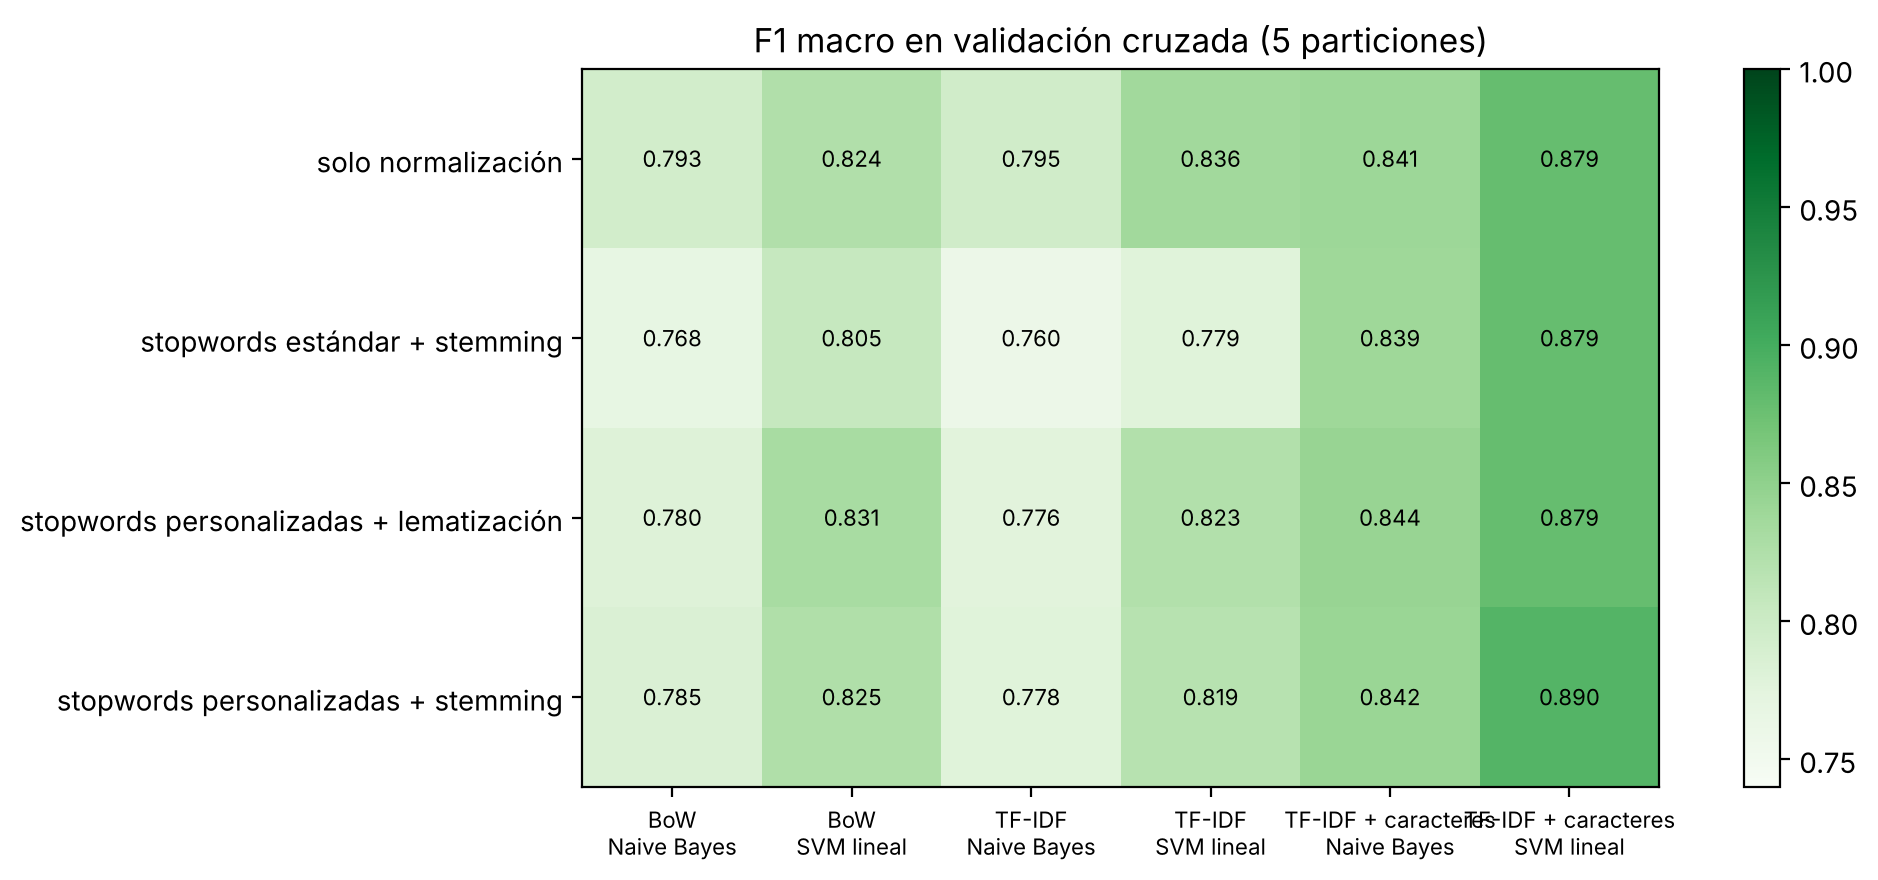

In [16]:
# Efecto promedio de cada decisión (promedio del F1 macro sobre las demás combinaciones)
for factor in ["preprocesamiento", "representación", "modelo"]:
    print(df_exp.groupby(factor)["F1 macro"].mean().sort_values(ascending=False).round(3), "\n")

fig, ax = plt.subplots(figsize=(10, 4.5))
tabla = df_exp.pivot_table(index="preprocesamiento", columns=["representación", "modelo"], values="F1 macro")
im = ax.imshow(tabla.values, cmap="Greens", vmin=tabla.values.min() - 0.02, vmax=1)
ax.set_yticks(range(len(tabla.index))); ax.set_yticklabels(tabla.index)
ax.set_xticks(range(len(tabla.columns))); ax.set_xticklabels([f"{r}\n{m}" for r, m in tabla.columns], fontsize=8)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        ax.text(j, i, f"{tabla.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
ax.set_title("F1 macro en validación cruzada (5 particiones)")
plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout()
plt.savefig("figuras/experimentos_texto.png", dpi=200, bbox_inches="tight"); plt.show()

In [17]:
# Configuración seleccionada: la de mayor F1 macro
mejor = df_exp.iloc[0]
STOP_SEL, RED_SEL = PREPROCESAMIENTOS[mejor["preprocesamiento"]]
REP_SEL, MOD_SEL = mejor["representación"], mejor["modelo"]
print(f"Seleccionado: {mejor['preprocesamiento']} | {REP_SEL} | {MOD_SEL} | F1 macro CV = {mejor['F1 macro']:.3f}")

def crear_clasificador():
    base = MODELOS[MOD_SEL]()
    # La SVM no produce probabilidades: se calibra con el método sigmoide (Platt) para poder fijar un umbral
    clf = CalibratedClassifierCV(base, method="sigmoid", cv=5) if MOD_SEL == "SVM lineal" else base
    return Pipeline([("vec", vectorizador(REP_SEL, STOP_SEL, RED_SEL)), ("clf", clf)])

# Interpretabilidad: términos con mayor peso por intención en la SVM (o mayor log-probabilidad en Naive Bayes)
interp = Pipeline([("vec", vectorizador(REP_SEL, STOP_SEL, RED_SEL)), ("clf", MODELOS[MOD_SEL]())]).fit(X_des, y_des)
vec = interp.named_steps["vec"]
nombres = (np.concatenate([np.array(["w:" + n for n in vec.transformer_list[0][1].get_feature_names_out()]),
                           np.array(["c:" + n for n in vec.transformer_list[1][1].get_feature_names_out()])])
           if isinstance(vec, FeatureUnion) else np.array(["w:" + n for n in vec.get_feature_names_out()]))
pesos = interp.named_steps["clf"].coef_ if MOD_SEL == "SVM lineal" else interp.named_steps["clf"].feature_log_prob_
terminos = {c: [nombres[i] for i in np.argsort(pesos[k])[::-1] if nombres[i].startswith("w:")][:6]
            for k, c in enumerate(interp.named_steps["clf"].classes_)}
pd.DataFrame({c: [t[2:] for t in v] for c, v in terminos.items()}).T.rename(columns=lambda i: f"término {i + 1}")

Seleccionado: stopwords personalizadas + stemming | TF-IDF + caracteres | SVM lineal | F1 macro CV = 0.890


,término 1,término 2,término 3,término 4,término 5,término 6
agendar_cita,cit,consult doctor,program,lun,agendam,program mi
consultar_cita,mi,mi cit,cuand,is104,cit,consult reserv
consultar_informacion,llev,pag,tarif,preci,preci consult,comun
derivar_humano,algui,cancel,human,person,cambi,habl
despedida,graci,tod,bien,suficient,no,vem
enviar_documento,envi,mand,fot,sub,imag,adjunt
orientacion_homeopatia,homeopat,homeopati auscult,auscult,diferent,pas primer,primer cit
saludo,hol,buen,tal,salud,hey,onda


### A4. Umbral de confianza para el fallback

Un clasificador siempre devuelve alguna intención. Para conservar el fallback del Avance 1, Inti acepta la predicción solo si la probabilidad máxima supera un umbral. El umbral se elige **sin tocar el bloque de prueba**: se comparan las probabilidades fuera de muestra (validación cruzada) de los mensajes del dominio con las de los 25 mensajes de calibración fuera de dominio, y se elige el valor que maximiza el índice de Youden (aceptados del dominio menos aceptados fuera de dominio).

Umbral elegido: 0.51 | dominio aceptado: 87.0% | fuera de dominio aceptado: 36.0%


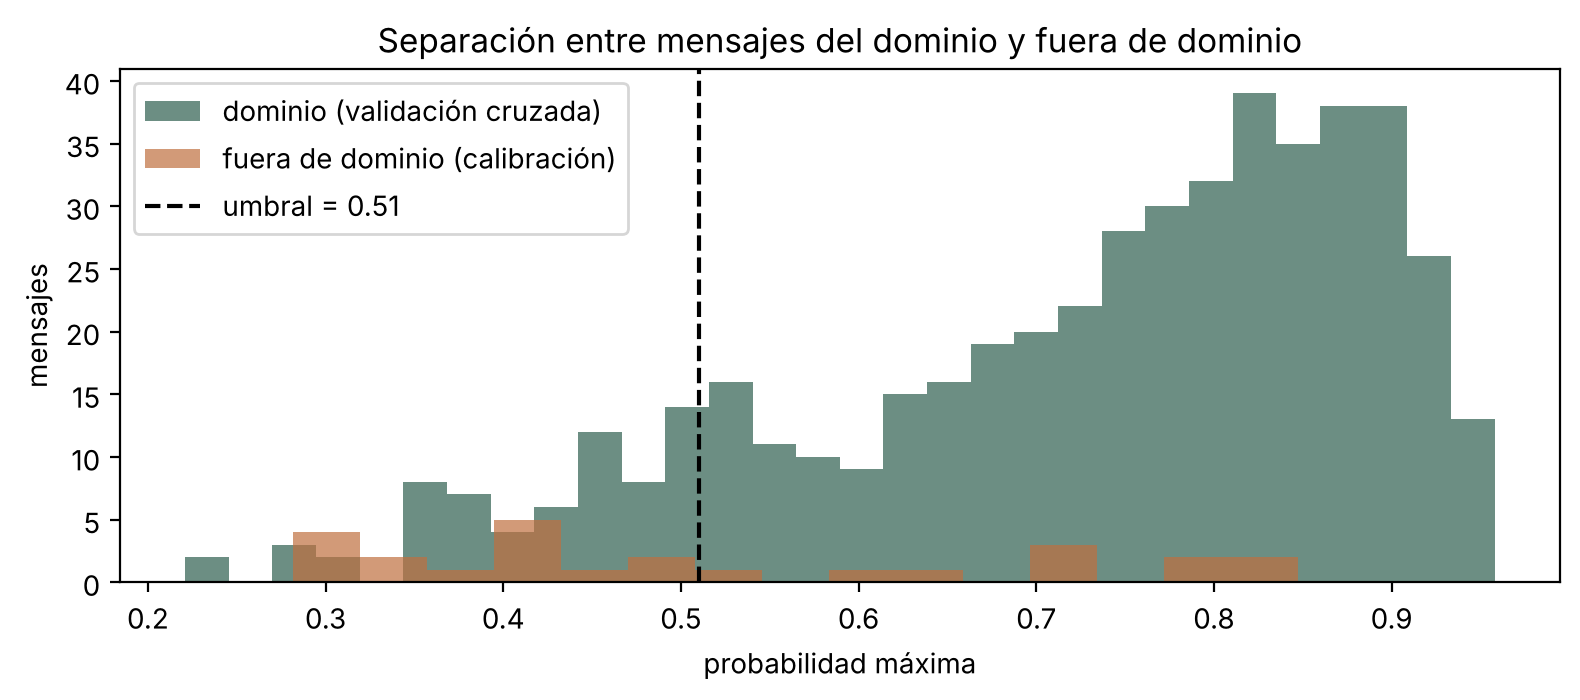

In [18]:
proba_oof = cross_val_predict(crear_clasificador(), X_des, y_des, cv=cv, method="predict_proba")
clasificador_texto = crear_clasificador().fit(X_des, y_des)
CLASES_TEXTO = list(clasificador_texto.classes_)
fuera_cal = df_texto[df_texto["conjunto"] == "fuera_dominio_calibracion"]["texto"].tolist()
p_dentro = proba_oof.max(axis=1)
p_fuera = clasificador_texto.predict_proba(fuera_cal).max(axis=1)

umbrales = np.round(np.arange(0.15, 0.81, 0.01), 2)
youden = [(p_dentro >= u).mean() - (p_fuera >= u).mean() for u in umbrales]
UMBRAL_TEXTO = float(umbrales[int(np.argmax(youden))])
print(f"Umbral elegido: {UMBRAL_TEXTO:.2f} | dominio aceptado: {(p_dentro >= UMBRAL_TEXTO).mean():.1%} "
      f"| fuera de dominio aceptado: {(p_fuera >= UMBRAL_TEXTO).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(p_dentro, bins=30, alpha=0.7, label="dominio (validación cruzada)", color="#2E5E4E")
ax.hist(p_fuera, bins=15, alpha=0.7, label="fuera de dominio (calibración)", color="#C0703F")
ax.axvline(UMBRAL_TEXTO, color="black", ls="--", label=f"umbral = {UMBRAL_TEXTO:.2f}")
ax.set_xlabel("probabilidad máxima"); ax.set_ylabel("mensajes"); ax.legend()
ax.set_title("Separación entre mensajes del dominio y fuera de dominio")
plt.tight_layout(); plt.savefig("figuras/umbral_texto.png", dpi=200, bbox_inches="tight"); plt.show()

### A5. Evaluación final en el bloque de prueba

In [19]:
X_pru, y_pru = prueba["texto"].tolist(), prueba["intencion"].tolist()
proba_pru = clasificador_texto.predict_proba(X_pru)
pred_pru = np.array(CLASES_TEXTO)[proba_pru.argmax(axis=1)]
pred_con_umbral = np.where(proba_pru.max(axis=1) >= UMBRAL_TEXTO, pred_pru, "fallback")

print("Clasificador sin umbral (120 mensajes de prueba)")
print(classification_report(y_pru, pred_pru, digits=3, zero_division=0))
acc_t = accuracy_score(y_pru, pred_pru)
p_t, r_t, f_t, _ = precision_recall_fscore_support(y_pru, pred_pru, average="macro", zero_division=0)
fuera_pru = df_texto[df_texto["conjunto"] == "fuera_dominio_prueba"]["texto"].tolist()
p_fuera_pru = clasificador_texto.predict_proba(fuera_pru).max(axis=1)
METRICAS_TEXTO = {
    "accuracy": acc_t, "precision_macro": p_t, "recall_macro": r_t, "f1_macro": f_t,
    "precision_intencion_con_umbral": (pred_con_umbral == np.array(y_pru)).mean(),
    "fallback_en_dominio": (pred_con_umbral == "fallback").mean(),
    "fallback_fuera_dominio": (p_fuera_pru < UMBRAL_TEXTO).mean(),
}
pd.Series(METRICAS_TEXTO).round(3).to_frame("valor")

Clasificador sin umbral (120 mensajes de prueba)
                        precision    recall  f1-score   support

          agendar_cita      0.929     0.867     0.897        15
        consultar_cita      0.933     0.933     0.933        15
 consultar_informacion      0.938     1.000     0.968        15
        derivar_humano      1.000     0.933     0.966        15
             despedida      1.000     1.000     1.000        15
      enviar_documento      1.000     1.000     1.000        15
orientacion_homeopatia      0.938     1.000     0.968        15
                saludo      1.000     1.000     1.000        15

              accuracy                          0.967       120
             macro avg      0.967     0.967     0.966       120
          weighted avg      0.967     0.967     0.966       120



,valor
accuracy,0.967
precision_macro,0.967
recall_macro,0.967
f1_macro,0.966
precision_intencion_con_umbral,0.958
fallback_en_dominio,0.017
fallback_fuera_dominio,0.467


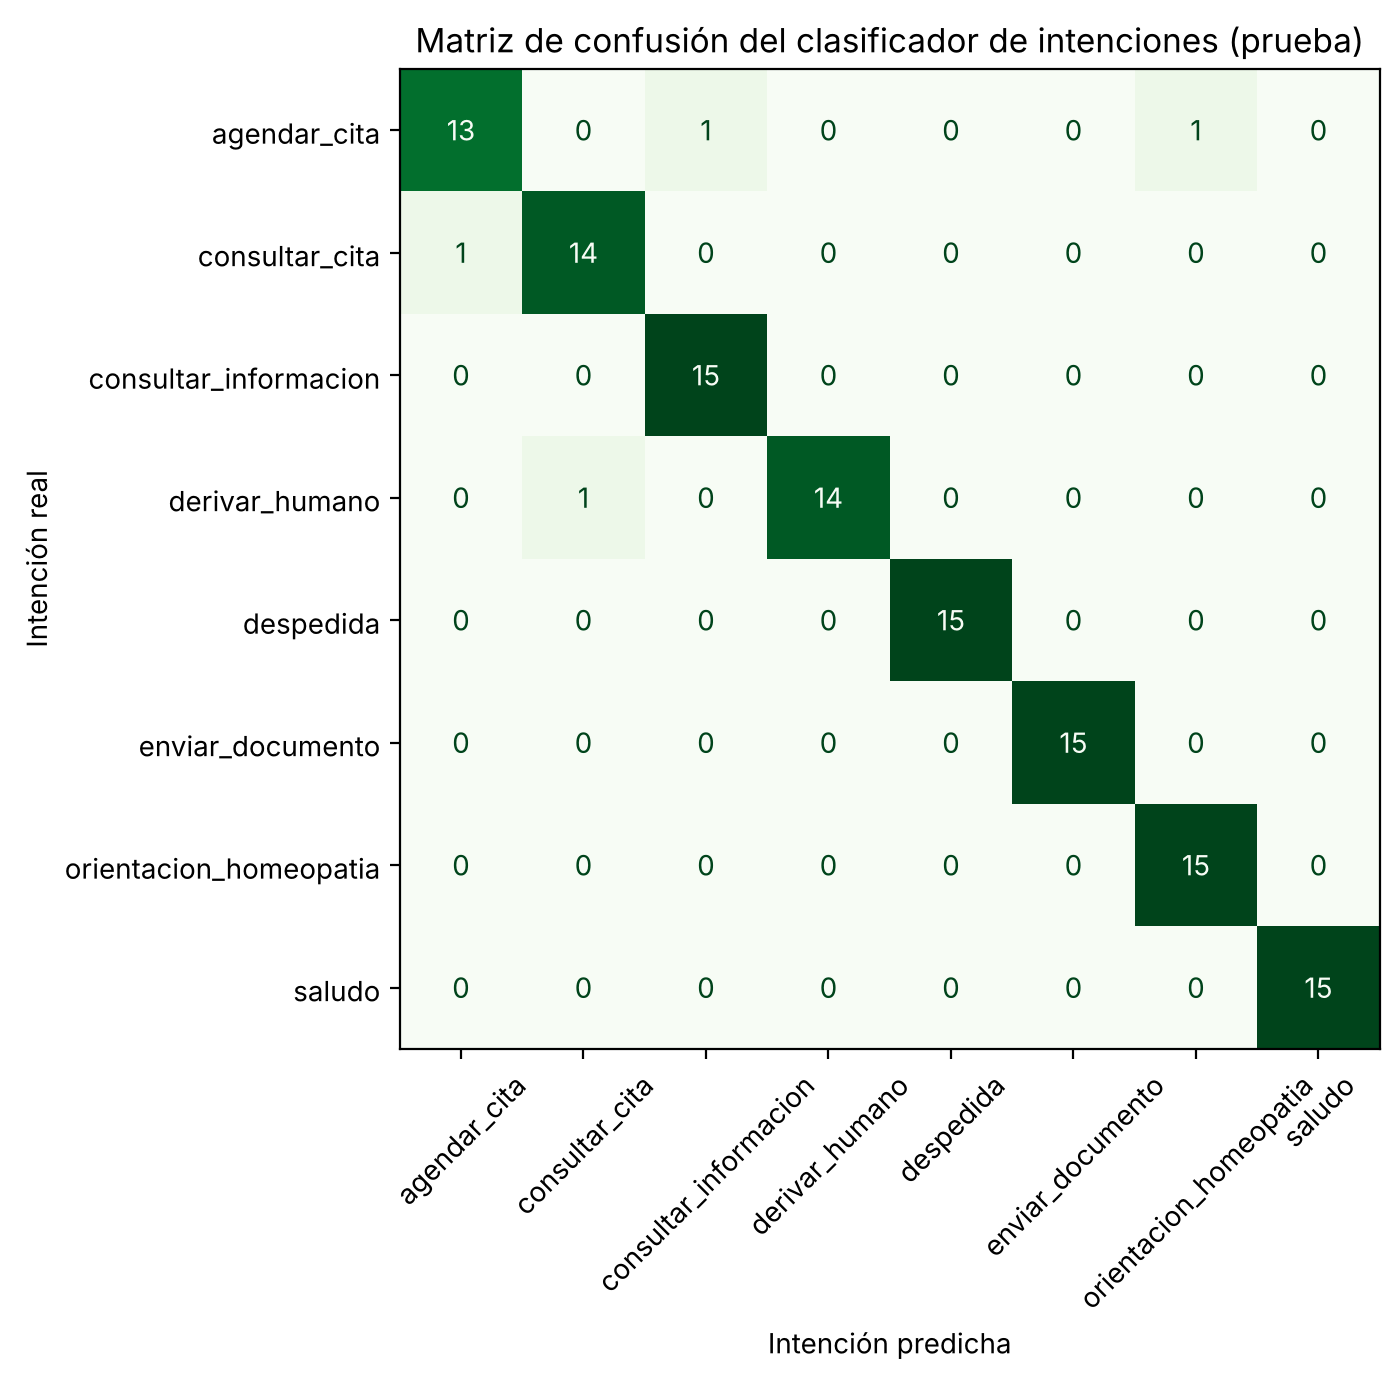

4 errores de clase y 2 mensajes bajo el umbral


,mensaje,real,predicho,probabilidad
49,necesito ver al doctor esta semana,agendar_cita,consultar_informacion,0.28
20,¿me da su correo para escribirles?,consultar_informacion,consultar_informacion,0.50
70,revísame la cita porfa,consultar_cita,agendar_cita,0.56
51,agéndeme para homeopatía,agendar_cita,orientacion_homeopatia,0.77
86,¿se puede recorrer mi cita?,derivar_humano,consultar_cita,0.81


In [20]:
fig, ax = plt.subplots(figsize=(8.5, 7))
ConfusionMatrixDisplay.from_predictions(y_pru, pred_pru, labels=CLASES_TEXTO, ax=ax, cmap="Greens",
                                        colorbar=False, xticks_rotation=45)
ax.set_title("Matriz de confusión del clasificador de intenciones (prueba)")
ax.set_xlabel("Intención predicha"); ax.set_ylabel("Intención real")
plt.tight_layout(); plt.savefig("figuras/matriz_confusion_texto.png", dpi=200, bbox_inches="tight"); plt.show()

errores_texto = pd.DataFrame({"mensaje": X_pru, "real": y_pru, "predicho": pred_pru,
                              "probabilidad": proba_pru.max(axis=1).round(2)})
errores_texto = errores_texto[(errores_texto["real"] != errores_texto["predicho"]) |
                              (errores_texto["probabilidad"] < UMBRAL_TEXTO)]
errores_texto.to_csv("pruebas/errores_texto.csv", index=False, encoding="utf-8-sig")
print(f"{(errores_texto['real'] != errores_texto['predicho']).sum()} errores de clase y "
      f"{(errores_texto['probabilidad'] < UMBRAL_TEXTO).sum()} mensajes bajo el umbral")
errores_texto.sort_values("probabilidad")

---
# Parte B. Componente de visión por computadora

## B1. Conjunto de imágenes

**Tarea.** Clasificar la imagen que un paciente envía antes de su consulta en cuatro categorías: `identificacion`, `receta_previa`, `estudio_laboratorio` y `otro`. Las tres primeras corresponden a los documentos que la base de conocimiento ya pide llevar a la consulta. Quedan fuera de alcance las imágenes clínicas (radiografías, lesiones, ultrasonidos), por ser terreno de dispositivos médicos regulados.

**Fuentes.** No se usan documentos reales de personas, por tratarse de datos personales sensibles. El conjunto combina:

1. **Documentos sintéticos** generados en este cuaderno con datos ficticios, diseño genérico y la marca "DATOS FICTICIOS". Ninguno imita el diseño de una institución real.
2. **Recibos reales escaneados** del conjunto público ICDAR 2019 SROIE (Huang et al., 2019), como parte de la clase `otro`.
3. **Fotografías públicas** de las imágenes de ejemplo de OpenCV (frutas, edificios, animales, objetos), también como `otro`.

**Control de atajos.** Si las tres clases de documento fueran sintéticas y `otro` fueran solo fotos reales, el modelo podría aprender a distinguir "imagen generada" de "foto real". Por eso `otro` incluye también documentos sintéticos ajenos al consultorio (tickets, cartas, menús y comprobantes) hechos con el mismo generador, y todas las imágenes de documentos pasan por la misma simulación de fotografía con celular.

**Partición sin fuga.** Se divide antes de aumentar. Cada recibo y cada escena de OpenCV pertenece a una sola partición. Los documentos sintéticos de prueba se generan con una tipografía que el modelo nunca ve en entrenamiento (STIX), para medir generalización a formatos nuevos.

In [21]:
# Generador de documentos sintéticos con datos ficticios para el clasificador visual de Inti.
# Ningún documento imita el diseño de una institución real: todos llevan la marca "DATOS FICTICIOS".
import os, random, math
import numpy as np
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
import matplotlib

FUENTES_DIR = os.path.join(matplotlib.get_data_path(), "fonts", "ttf")
# Fuentes de entrenamiento y validación; la fuente de prueba se reserva para medir generalización
FUENTES = {
    "entrenamiento": [("DejaVuSans.ttf", "DejaVuSans-Bold.ttf"),
                      ("DejaVuSerif.ttf", "DejaVuSerif-Bold.ttf"),
                      ("DejaVuSansMono.ttf", "DejaVuSansMono-Bold.ttf")],
    "prueba": [("STIXGeneral.ttf", "STIXGeneralBol.ttf")],
}

NOMBRES = ["María", "José", "Guadalupe", "Juan", "Ana", "Luis", "Rosa", "Carlos", "Laura", "Jorge",
           "Patricia", "Miguel", "Elena", "Fernando", "Sofía", "Ricardo", "Teresa", "Alejandro", "Lucía", "Andrés"]
APELLIDOS = ["Hernández", "García", "Martínez", "López", "González", "Pérez", "Rodríguez", "Sánchez",
             "Ramírez", "Cruz", "Flores", "Gómez", "Morales", "Vázquez", "Reyes", "Jiménez", "Torres", "Ruiz"]
CALLES = ["Av. Ejemplo", "Calle Prueba", "Calle Ficticia", "Av. Modelo", "Privada Muestra", "Calle Demostración"]
COLORES = [(46, 94, 78), (30, 70, 120), (120, 40, 40), (90, 60, 120), (40, 100, 110), (150, 90, 40), (60, 60, 60)]
ANALITOS = [("Glucosa", "mg/dL", (70, 99)), ("Urea", "mg/dL", (15, 45)), ("Creatinina", "mg/dL", (0.6, 1.2)),
            ("Colesterol total", "mg/dL", (120, 200)), ("Triglicéridos", "mg/dL", (50, 150)),
            ("Ácido úrico", "mg/dL", (3.5, 7.2)), ("Hemoglobina", "g/dL", (12, 17)), ("Hematocrito", "%", (36, 50)),
            ("Leucocitos", "10^3/µL", (4.5, 11)), ("Plaquetas", "10^3/µL", (150, 400)), ("TSH", "µUI/mL", (0.4, 4.0)),
            ("Colesterol HDL", "mg/dL", (40, 60)), ("Colesterol LDL", "mg/dL", (60, 130))]
SECCIONES_LAB = ["QUÍMICA SANGUÍNEA", "BIOMETRÍA HEMÁTICA", "PERFIL DE LÍPIDOS", "PERFIL TIROIDEO", "EXAMEN GENERAL"]
PLATILLOS = ["Sopa del día", "Enchiladas verdes", "Tacos de guisado", "Ensalada de la casa", "Pescado empapelado",
             "Chilaquiles rojos", "Agua de jamaica", "Café de olla", "Flan napolitano", "Arroz con leche"]
PRODUCTOS = ["Papel bond", "Bolígrafos", "Cuaderno", "Leche 1 L", "Pan de caja", "Detergente", "Jabón",
             "Refresco", "Galletas", "Pilas AA", "Cable USB", "Tornillos", "Pintura 1 L"]


def fuente(nombre, tam):
    return ImageFont.truetype(os.path.join(FUENTES_DIR, nombre), tam)


def nombre_ficticio(rng):
    return f"{rng.choice(NOMBRES)} {rng.choice(APELLIDOS)} {rng.choice(APELLIDOS)}"


def lienzo(ancho, alto, rng):
    papel = tuple(int(c) for c in np.array([250, 248, 240]) - rng.integers(0, 12, 3))
    return Image.new("RGB", (ancho, alto), papel)


def marca_ficticia(img, f_regular, rng):
    # Marca de agua diagonal presente en todos los documentos sintéticos de todas las clases
    capa = Image.new("RGBA", img.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(capa)
    tam = max(14, img.size[0] // 18)
    d.text((img.size[0] * 0.18, img.size[1] * 0.45), "DATOS FICTICIOS", fill=(150, 150, 150, 70), font=fuente(f_regular, tam))
    capa = capa.rotate(rng.uniform(15, 35), center=(img.size[0] / 2, img.size[1] / 2))
    return Image.alpha_composite(img.convert("RGBA"), capa).convert("RGB")


def firma(d, x, y, ancho, rng, color=(30, 30, 80)):
    puntos = [(x + i * ancho / 12, y + rng.normal(0, 6)) for i in range(13)]
    d.line(puntos, fill=color, width=2)
    d.line([(x, y + 14), (x + ancho, y + 14)], fill=(80, 80, 80), width=1)


def doc_identificacion(rng, fuentes):
    fr, fb = fuentes
    w, h = 640, 404
    img = lienzo(w, h, rng); d = ImageDraw.Draw(img)
    color = COLORES[rng.integers(len(COLORES))]
    alto_banda = int(rng.integers(55, 80))
    d.rectangle([0, 0, w, alto_banda], fill=color)
    titulo = rng.choice(["IDENTIFICACIÓN DE PRUEBA", "CREDENCIAL FICTICIA", "DOCUMENTO DE IDENTIDAD DE PRUEBA"])
    d.text((20, alto_banda / 2 - 12), titulo, fill="white", font=fuente(fb, 24))
    # Fotografía de silueta genérica (sin rostros reales)
    fx, fy = (20, alto_banda + 20) if rng.random() < 0.7 else (w - 170, alto_banda + 20)
    d.rectangle([fx, fy, fx + 140, fy + 175], fill=(205, 210, 215), outline=(120, 120, 120))
    d.ellipse([fx + 42, fy + 25, fx + 98, fy + 85], fill=(150, 155, 165))
    d.pieslice([fx + 15, fy + 95, fx + 125, fy + 215], 180, 360, fill=(150, 155, 165))
    tx = fx + 165 if fx < 100 else 25
    y = alto_banda + 20
    campos = [("NOMBRE", nombre_ficticio(rng).upper()),
              ("DOMICILIO", f"{rng.choice(CALLES).upper()} {rng.integers(1, 999)}"),
              ("CLAVE DE PRUEBA", "".join(rng.choice(list("ABCDEFGHJKLMNPQRSTUVWXYZ0123456789"), 12))),
              ("VIGENCIA", f"20{rng.integers(26, 36)}")]
    for etiqueta, valor in campos:
        d.text((tx, y), etiqueta, fill=(110, 110, 110), font=fuente(fr, 13)); y += 17
        d.text((tx, y), valor, fill=(20, 20, 20), font=fuente(fb, 18)); y += 32
    firma(d, tx, h - 55, 180, rng)
    if rng.random() < 0.6:  # código de barras genérico
        bx = w - 230
        for i in range(60):
            if rng.random() < 0.6:
                d.rectangle([bx + i * 3, h - 50, bx + i * 3 + 1, h - 15], fill=(20, 20, 20))
    return marca_ficticia(img, fr, rng)


def encabezado_medico(d, w, rng, fr, fb, color):
    doctor = ("Dra. " if rng.random() < 0.5 else "Dr. ") + nombre_ficticio(rng)
    d.text((40, 30), doctor, fill=color, font=fuente(fb, 30))
    d.text((40, 70), rng.choice(["Médico cirujano", "Medicina general", "Médico familiar"]), fill=(60, 60, 60), font=fuente(fr, 18))
    d.text((40, 95), f"Cédula profesional {rng.integers(1000000, 9999999)} (ficticia)", fill=(60, 60, 60), font=fuente(fr, 16))
    d.line([(40, 125), (w - 40, 125)], fill=color, width=3)


def doc_receta(rng, fuentes):
    fr, fb = fuentes
    w, h = (620, 800) if rng.random() < 0.6 else (800, 560)
    img = lienzo(w, h, rng); d = ImageDraw.Draw(img)
    color = COLORES[rng.integers(len(COLORES))]
    encabezado_medico(d, w, rng, fr, fb, color)
    d.text((40, 140), f"Paciente: {nombre_ficticio(rng)}", fill=(30, 30, 30), font=fuente(fr, 18))
    d.text((w - 230, 140), f"Fecha: {rng.integers(1, 28):02d}/{rng.integers(1, 12):02d}/2026", fill=(30, 30, 30), font=fuente(fr, 18))
    if rng.random() < 0.7:
        d.text((40, 168), f"Edad: {rng.integers(18, 85)} años   Peso: {rng.integers(50, 95)} kg", fill=(30, 30, 30), font=fuente(fr, 16))
    d.text((40, 200), "Rx", fill=color, font=fuente(fb, 48))
    y = 270
    for i in range(int(rng.integers(2, 5))):
        letra = "ABCDEFG"[i]
        d.text((70, y), f"{i + 1}. Medicamento de prueba {letra} {rng.choice([5, 10, 50, 100, 250, 500])} mg", fill=(25, 25, 60), font=fuente(fr, 18))
        d.text((95, y + 24), "Indicación de ejemplo, según criterio médico.", fill=(70, 70, 70), font=fuente(fr, 15))
        y += 62
        if y > h - 140: break
    firma(d, w - 260, h - 110, 200, rng)
    d.text((w - 250, h - 85), "Firma del médico", fill=(90, 90, 90), font=fuente(fr, 14))
    d.text((40, h - 45), f"{rng.choice(CALLES)} {rng.integers(1, 999)}, consultorio de ejemplo", fill=(90, 90, 90), font=fuente(fr, 14))
    return marca_ficticia(img, fr, rng)


def doc_laboratorio(rng, fuentes):
    fr, fb = fuentes
    w, h = 620, 820
    img = lienzo(w, h, rng); d = ImageDraw.Draw(img)
    color = COLORES[rng.integers(len(COLORES))]
    d.rectangle([0, 0, w, 90], fill=color)
    d.text((30, 18), rng.choice(["Laboratorio de análisis clínicos", "Laboratorio clínico de prueba", "Análisis clínicos ejemplo"]),
           fill="white", font=fuente(fb, 26))
    d.text((30, 55), "Resultados de laboratorio (ficticio)", fill="white", font=fuente(fr, 16))
    d.text((30, 105), f"Paciente: {nombre_ficticio(rng)}", fill=(30, 30, 30), font=fuente(fr, 16))
    d.text((30, 128), f"Folio: {rng.integers(100000, 999999)}    Fecha de toma: {rng.integers(1, 28):02d}/{rng.integers(1, 12):02d}/2026",
           fill=(30, 30, 30), font=fuente(fr, 15))
    y = 165
    for _ in range(int(rng.integers(1, 3))):
        d.text((30, y), rng.choice(SECCIONES_LAB), fill=color, font=fuente(fb, 17)); y += 28
        cols = [30, 215, 315, 440]
        for x, t in zip(cols, ["Estudio", "Resultado", "Unidades", "Referencia"]):
            d.text((x, y), t, fill=(60, 60, 60), font=fuente(fb, 14))
        y += 20; d.line([(30, y), (w - 30, y)], fill=(120, 120, 120), width=1); y += 6
        idx = rng.choice(len(ANALITOS), int(rng.integers(5, 9)), replace=False)
        for k in idx:
            nombre, unidad, (lo, hi) = ANALITOS[k]
            valor = rng.uniform(lo * 0.8, hi * 1.2)
            texto_valor = f"{valor:.1f}" if hi < 20 else f"{valor:.0f}"
            for x, t in zip(cols, [nombre, texto_valor, unidad, f"{lo} a {hi}"]):
                d.text((x, y), t, fill=(25, 25, 25), font=fuente(fr, 14))
            y += 22
            if rng.random() < 0.5: d.line([(30, y - 2), (w - 30, y - 2)], fill=(225, 225, 225), width=1)
        y += 20
        if y > h - 200: break
    d.text((30, h - 70), "Responsable sanitario: Q.F.B. " + nombre_ficticio(rng) + " (ficticio)", fill=(80, 80, 80), font=fuente(fr, 13))
    firma(d, w - 230, h - 120, 180, rng)
    return marca_ficticia(img, fr, rng)


def doc_distractor(rng, fuentes):
    # Documentos ajenos al consultorio, generados con el mismo motor para evitar atajos de estilo
    fr, fb = fuentes
    tipo = rng.choice(["ticket", "carta", "menu", "factura"])
    if tipo == "ticket":
        w, h = 360, 760
        img = lienzo(w, h, rng); d = ImageDraw.Draw(img)
        d.text((40, 30), rng.choice(["TIENDA DE EJEMPLO", "SUPER MUESTRA", "PAPELERÍA PRUEBA"]), fill=(20, 20, 20), font=fuente(fb, 22))
        d.text((40, 65), f"Ticket {rng.integers(1000, 9999)}  Caja {rng.integers(1, 9)}", fill=(40, 40, 40), font=fuente(fr, 15))
        y, total = 110, 0
        for _ in range(int(rng.integers(5, 14))):
            p = rng.uniform(10, 250); total += p
            d.text((30, y), rng.choice(PRODUCTOS), fill=(30, 30, 30), font=fuente(fr, 15))
            d.text((260, y), f"${p:,.2f}", fill=(30, 30, 30), font=fuente(fr, 15)); y += 26
        d.text((30, y + 15), f"TOTAL  ${total:,.2f}", fill=(10, 10, 10), font=fuente(fb, 20))
        d.text((30, y + 55), "Gracias por su compra", fill=(40, 40, 40), font=fuente(fr, 15))
    elif tipo == "carta":
        w, h = 620, 800
        img = lienzo(w, h, rng); d = ImageDraw.Draw(img)
        d.text((40, 40), f"Ciudad de ejemplo, {rng.integers(1, 28)} de noviembre de 2026", fill=(30, 30, 30), font=fuente(fr, 16))
        d.text((40, 90), f"Estimado(a) {nombre_ficticio(rng)}:", fill=(30, 30, 30), font=fuente(fb, 18))
        palabras = "por medio de la presente le informamos que la reunión vecinal se llevará a cabo en el salón comunitario y le pedimos confirmar su asistencia con anticipación".split()
        y = 140
        for _ in range(int(rng.integers(10, 18))):
            linea = " ".join(rng.choice(palabras, int(rng.integers(6, 10))))
            d.text((40, y), linea.capitalize(), fill=(40, 40, 40), font=fuente(fr, 16)); y += 28
        d.text((40, y + 30), "Atentamente,", fill=(30, 30, 30), font=fuente(fr, 16))
        firma(d, 40, y + 80, 180, rng)
    elif tipo == "menu":
        w, h = 620, 800
        img = lienzo(w, h, rng); d = ImageDraw.Draw(img)
        color = COLORES[rng.integers(len(COLORES))]
        d.text((150, 40), rng.choice(["MENÚ DEL DÍA", "CARTA DE EJEMPLO", "COCINA MUESTRA"]), fill=color, font=fuente(fb, 34))
        y = 140
        for p in rng.choice(PLATILLOS, int(rng.integers(6, 10)), replace=False):
            d.text((60, y), p, fill=(30, 30, 30), font=fuente(fr, 20))
            d.text((470, y), f"${rng.integers(30, 220)}", fill=(30, 30, 30), font=fuente(fb, 20)); y += 55
    else:
        w, h = 800, 620
        img = lienzo(w, h, rng); d = ImageDraw.Draw(img)
        d.text((40, 30), "COMPROBANTE DE VENTA DE EJEMPLO", fill=(20, 20, 20), font=fuente(fb, 24))
        d.text((40, 70), f"Cliente: {nombre_ficticio(rng)}", fill=(40, 40, 40), font=fuente(fr, 16))
        y = 120
        for x, t in zip([40, 400, 520, 640], ["Concepto", "Cant.", "Precio", "Importe"]):
            d.text((x, y), t, fill=(20, 20, 20), font=fuente(fb, 16))
        y += 30
        for _ in range(int(rng.integers(4, 10))):
            c, p = int(rng.integers(1, 6)), rng.uniform(20, 900)
            for x, t in zip([40, 400, 520, 640], [rng.choice(PRODUCTOS), str(c), f"{p:,.2f}", f"{c * p:,.2f}"]):
                d.text((x, y), t, fill=(40, 40, 40), font=fuente(fr, 15))
            y += 28
    return marca_ficticia(img, fr, rng)


GENERADORES = {"identificacion": doc_identificacion, "receta_previa": doc_receta,
               "estudio_laboratorio": doc_laboratorio, "otro": doc_distractor}


def _coef_perspectiva(origen, destino):
    m = []
    for (x, y), (u, v) in zip(destino, origen):
        m.append([x, y, 1, 0, 0, 0, -u * x, -u * y]); m.append([0, 0, 0, x, y, 1, -v * x, -v * y])
    return np.linalg.solve(np.array(m, float), np.array(origen, float).reshape(8))


def fondo(tam, rng):
    base = np.array(rng.choice([[120, 90, 60], [180, 170, 150], [90, 90, 95], [200, 200, 205], [60, 70, 80], [150, 120, 100]]), float)
    ruido = rng.normal(0, 12, (tam, tam, 1)) + np.linspace(-25, 25, tam)[None, :, None] * rng.uniform(-1, 1)
    return Image.fromarray(np.clip(base + ruido, 0, 255).astype(np.uint8))


def fotografiar(doc, rng, tam=448, sobre_fondo=True):
    # Simula una foto tomada con celular: fondo, perspectiva, rotación, iluminación, desenfoque, ruido y compresión
    escala = rng.uniform(0.72, 0.92) * tam / max(doc.size)
    doc = doc.resize((max(1, int(doc.size[0] * escala)), max(1, int(doc.size[1] * escala))))
    w, h = doc.size
    j = 0.06
    destino = [(rng.uniform(0, j) * w, rng.uniform(0, j) * h), (w - rng.uniform(0, j) * w, rng.uniform(0, j) * h),
               (w - rng.uniform(0, j) * w, h - rng.uniform(0, j) * h), (rng.uniform(0, j) * w, h - rng.uniform(0, j) * h)]
    coef = _coef_perspectiva([(0, 0), (w, 0), (w, h), (0, h)], destino)
    mascara = Image.new("L", (w, h), 255).transform((w, h), Image.PERSPECTIVE, coef, Image.BILINEAR)
    doc = doc.transform((w, h), Image.PERSPECTIVE, coef, Image.BILINEAR)
    angulo = rng.uniform(-7, 7)
    doc = doc.rotate(angulo, expand=True, resample=Image.BILINEAR)
    mascara = mascara.rotate(angulo, expand=True)
    lienzo_final = fondo(tam, rng) if sobre_fondo else Image.new("RGB", (tam, tam), (255, 255, 255))
    x = int(rng.uniform(0, max(1, tam - doc.size[0]))); y = int(rng.uniform(0, max(1, tam - doc.size[1])))
    lienzo_final.paste(doc, (x, y), mascara)
    arr = np.asarray(lienzo_final).astype(float)
    gradiente = np.linspace(rng.uniform(0.75, 1.0), rng.uniform(0.95, 1.12), tam)
    arr = arr * (gradiente[None, :, None] if rng.random() < 0.5 else gradiente[:, None, None])
    arr = arr + rng.normal(0, rng.uniform(0, 7), arr.shape)
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    img = img.filter(ImageFilter.GaussianBlur(rng.uniform(0, 1.1)))
    return img

In [22]:
# Descarga de las fuentes públicas (recibos SROIE y escenas de OpenCV) desde GitHub
URL_SROIE = "https://raw.githubusercontent.com/zzzDavid/ICDAR-2019-SROIE/master/data/img/{:03d}.jpg"
URL_OPENCV = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/{}"
ESCENAS_OPENCV = {  # una escena por grupo para que ninguna aparezca en dos particiones
    "entrenamiento": ["aero1.jpg", "apple.jpg", "baboon.jpg", "board.jpg", "building.jpg", "butterfly.jpg",
                      "fruits.jpg", "home.jpg", "orange.jpg", "HappyFish.jpg", "blox.jpg", "smarties.png"],
    "validacion": ["graf1.png", "cards.png", "gauge-1.jpg"],
    "prueba": ["leuvenA.jpg", "squirrel_cls.jpg", "stuff.jpg", "box_in_scene.png"],
}

def descargar(url, destino):
    if not os.path.exists(destino):
        urllib.request.urlretrieve(url, destino)
    return destino

os.makedirs("datos/publicas", exist_ok=True)
rng_pub = np.random.default_rng(SEMILLA)
ids_sroie = rng_pub.choice(626, 100, replace=False)
SROIE = {"entrenamiento": ids_sroie[:64], "validacion": ids_sroie[64:80], "prueba": ids_sroie[80:]}
for particion, ids in SROIE.items():
    for i in ids:
        descargar(URL_SROIE.format(i), f"datos/publicas/sroie_{i:03d}.jpg")
for particion, escenas in ESCENAS_OPENCV.items():
    for e in escenas:
        descargar(URL_OPENCV.format(e), f"datos/publicas/opencv_{e}")
print("Imágenes públicas descargadas:", len(os.listdir("datos/publicas")))

Imágenes públicas descargadas: 119


In [23]:
# Construcción del conjunto: 250 imágenes por clase (160 entrenamiento, 40 validación, 50 prueba)
TAM = {"entrenamiento": 160, "validacion": 40, "prueba": 50}
COMPOSICION_OTRO = {  # (sintéticos, recibos SROIE, recortes por escena de OpenCV)
    "entrenamiento": (60, 64, 3), "validacion": (15, 16, 3), "prueba": (18, 20, 3)}
CLASES_VISION = ["estudio_laboratorio", "identificacion", "otro", "receta_previa"]

def recorte_natural(ruta, rng, tam=448):
    img = Image.open(ruta).convert("RGB")
    w, h = img.size
    lado = int(min(w, h) * rng.uniform(0.6, 1.0))
    x, y = int(rng.uniform(0, w - lado)), int(rng.uniform(0, h - lado))
    return img.crop((x, y, x + lado, y + lado)).resize((tam, tam))

def guardar(img, ruta, rng):
    img.save(ruta, quality=int(rng.integers(60, 93)))  # compresión JPEG variable, como en un celular

def construir_imagenes(raiz="datos/imagenes"):
    filas = []
    for k, (particion, n) in enumerate(TAM.items()):
        rng = np.random.default_rng(SEMILLA + k)
        fuentes = FUENTES["prueba"] if particion == "prueba" else FUENTES["entrenamiento"]
        for clase in CLASES_VISION:
            carpeta = f"{raiz}/{particion}/{clase}"; os.makedirs(carpeta, exist_ok=True)
            elementos = []
            if clase != "otro":
                elementos += [("sintetico", None)] * n
            else:
                n_sint, _, recortes = COMPOSICION_OTRO[particion]
                elementos += [("sintetico", None)] * n_sint
                elementos += [("sroie", f"datos/publicas/sroie_{i:03d}.jpg") for i in SROIE[particion]]
                elementos += [("opencv", f"datos/publicas/opencv_{e}") for e in ESCENAS_OPENCV[particion] for _ in range(recortes)]
                elementos = elementos[:n]
            for j, (fuente_img, ruta_origen) in enumerate(elementos):
                if fuente_img == "sintetico":
                    f = fuentes[int(rng.integers(len(fuentes)))]
                    img = fotografiar(GENERADORES[clase](rng, f), rng)
                elif fuente_img == "sroie":
                    img = fotografiar(Image.open(ruta_origen).convert("RGB"), rng)
                else:
                    img = recorte_natural(ruta_origen, rng)
                ruta = f"{carpeta}/{fuente_img}_{j:03d}.jpg"
                guardar(img, ruta, rng)
                filas.append({"ruta": ruta, "particion": particion, "clase": clase, "fuente": fuente_img})
    return pd.DataFrame(filas)

t0 = time.time()
df_img = construir_imagenes()
df_img.to_csv("datos/manifiesto_imagenes.csv", index=False, encoding="utf-8-sig")
print(f"{len(df_img)} imágenes generadas en {time.time() - t0:.0f} s")
pd.crosstab([df_img["clase"], df_img["fuente"]], df_img["particion"], margins=True, margins_name="total")

1000 imágenes generadas en 50 s


particion                      entrenamiento  prueba  validacion  total
clase               fuente                                             
estudio_laboratorio sintetico            160      50          40    250
identificacion      sintetico            160      50          40    250
otro                opencv                36      12           9     57
                    sintetico             60      18          15     93
                    sroie                 64      20          16    100
receta_previa       sintetico            160      50          40    250
total                                    640     200         160   1000

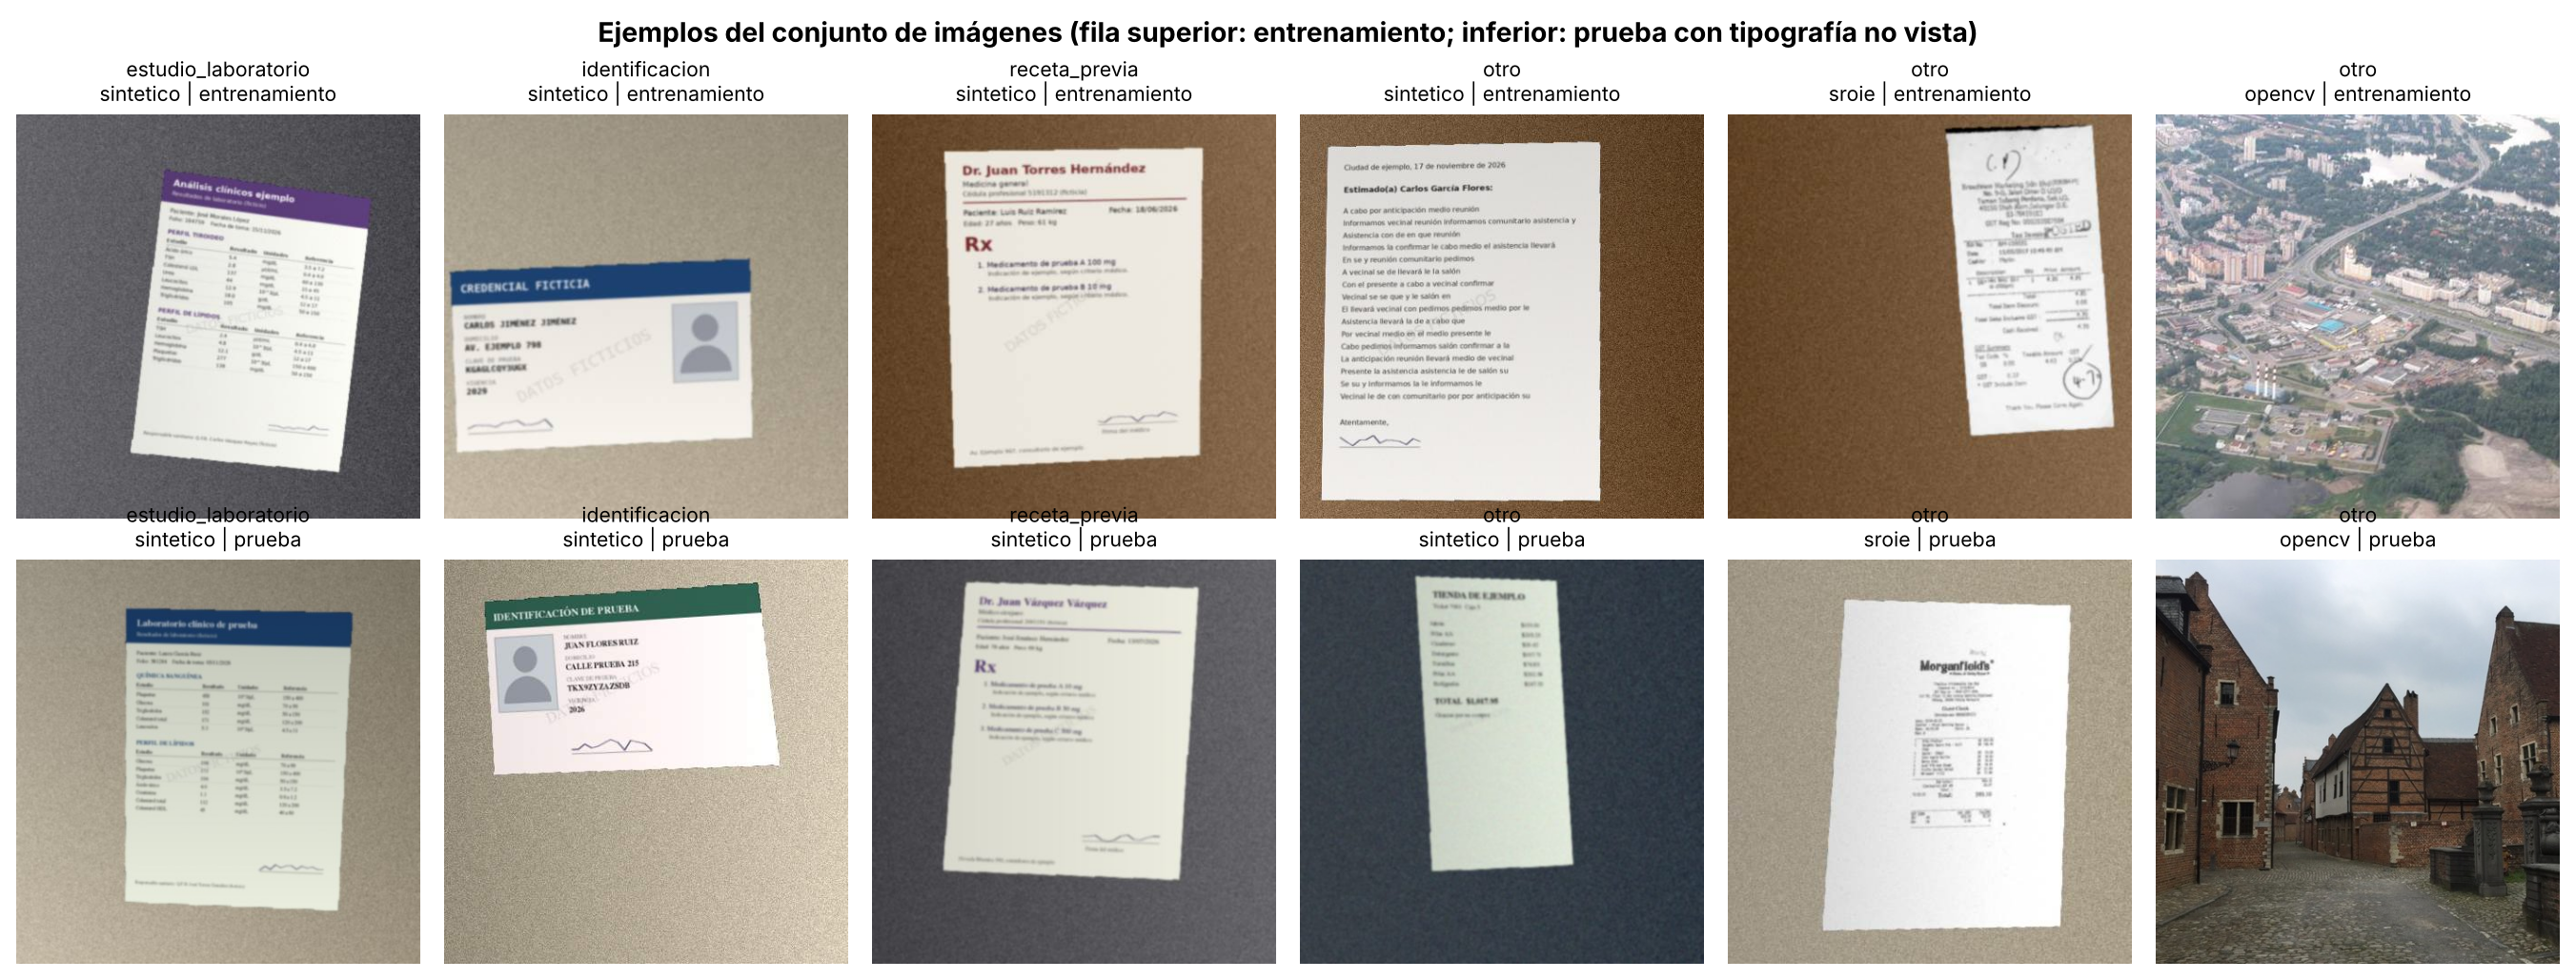

In [24]:
columnas = [("estudio_laboratorio", "sintetico"), ("identificacion", "sintetico"), ("receta_previa", "sintetico"),
            ("otro", "sintetico"), ("otro", "sroie"), ("otro", "opencv")]
fig, axes = plt.subplots(2, 6, figsize=(16, 6.2))
for fila_ax, particion in zip(axes, ["entrenamiento", "prueba"]):
    for ax, (clase, fuente) in zip(fila_ax, columnas):
        ruta = df_img[(df_img["particion"] == particion) & (df_img["clase"] == clase) & (df_img["fuente"] == fuente)]["ruta"].iloc[0]
        ax.imshow(Image.open(ruta)); ax.axis("off"); ax.set_title(f"{clase}\n{fuente} | {particion}", fontsize=9)
plt.suptitle("Ejemplos del conjunto de imágenes (fila superior: entrenamiento; inferior: prueba con tipografía no vista)", fontweight="bold")
plt.tight_layout(); plt.savefig("figuras/ejemplos_imagenes.png", dpi=170, bbox_inches="tight"); plt.show()

## B2. Preprocesamiento y aumento de datos

Se usan dos pipelines, como en el Tema 8. El de **entrenamiento** es aleatorio: rotación leve, perspectiva, recorte con zoom moderado y variación de brillo y contraste. **No se usan volteos**, porque un documento con el texto espejado no existe en la realidad y el aumento cambiaría la distribución de la clase. El de **validación y prueba** es determinista. Ambos normalizan con la media y la desviación estándar de ImageNet, que es la distribución con la que se preentrenó la red.

In [25]:
MEDIA, DESV = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
TAM_ENTRADA = 224
transform_entrenamiento = T.Compose([
    T.Resize((TAM_ENTRADA + 16, TAM_ENTRADA + 16)),
    T.RandomRotation(6, fill=128),
    T.RandomPerspective(distortion_scale=0.15, p=0.3, fill=128),
    T.RandomResizedCrop(TAM_ENTRADA, scale=(0.8, 1.0), ratio=(0.95, 1.05)),
    T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.02),
    T.ToTensor(), T.Normalize(MEDIA, DESV)])
transform_evaluacion = T.Compose([T.Resize((TAM_ENTRADA, TAM_ENTRADA)), T.ToTensor(), T.Normalize(MEDIA, DESV)])

class ConjuntoImagenes(Dataset):
    def __init__(self, df, transform):
        self.rutas, self.y, self.transform = df["ruta"].tolist(), [CLASES_VISION.index(c) for c in df["clase"]], transform
    def __len__(self): return len(self.rutas)
    def __getitem__(self, i): return self.transform(Image.open(self.rutas[i]).convert("RGB")), self.y[i]

def cargador(particion, transform, mezclar):
    return DataLoader(ConjuntoImagenes(df_img[df_img["particion"] == particion], transform),
                      batch_size=32, shuffle=mezclar, num_workers=2)

cargador_ent = cargador("entrenamiento", transform_entrenamiento, True)
cargador_val = cargador("validacion", transform_evaluacion, False)
cargador_pru = cargador("prueba", transform_evaluacion, False)
x, y = next(iter(cargador_ent))
print("Forma de un lote:", tuple(x.shape), "| media por canal:", x.mean(dim=(0, 2, 3)).numpy().round(2))

Forma de un lote: (32, 3, 224, 224) | media por canal: [0.53 0.59 0.7 ]


## B3. Arquitectura y entrenamiento con transferencia de aprendizaje

Se usa **EfficientNet-B0** preentrenada en ImageNet (Tan y Le, 2019). Se eligió sobre ResNet50 porque tiene alrededor de 5.3 millones de parámetros con su capa original de 1000 clases (4.0 millones con la capa de 4 clases de este proyecto) frente a 25.6 millones de ResNet50, entrena en CPU y GPU en minutos y, en el trabajo original, alcanza mayor exactitud en ImageNet con menos cómputo. La capa final de 1000 clases se sustituye por una de 4.

El entrenamiento tiene dos etapas:

1. **Extracción de características:** toda la red congelada; solo se entrena la capa de clasificación (8 épocas, tasa de aprendizaje 1e-3).
2. **Ajuste fino:** se descongelan los tres últimos bloques convolucionales y la cabeza (6 épocas, tasa 2e-4). Las capas de normalización por lotes congeladas se mantienen en modo de evaluación para no alterar sus estadísticas de ImageNet.

Se guarda el modelo con mayor F1 macro en validación.

In [26]:
modelo_vision = EfficientNet.from_pretrained("efficientnet-b0", num_classes=len(CLASES_VISION)).to(DISPOSITIVO)
print(f"Parámetros totales: {sum(p.numel() for p in modelo_vision.parameters()) / 1e6:.2f} millones")

def configurar_etapa(modelo, etapa):
    for p in modelo.parameters(): p.requires_grad = False
    entrenables = [modelo._fc]
    if etapa == 2:
        entrenables += [modelo._blocks[-3:], modelo._conv_head, modelo._bn1]
    for m in entrenables:
        for p in m.parameters(): p.requires_grad = True
    return entrenables

def poner_en_modo_entrenamiento(modelo, entrenables):
    modelo.eval()  # congeladas, incluida la normalización por lotes, en modo evaluación
    for m in entrenables: m.train()
    modelo._dropout.train()

def evaluar(modelo, cargador_eval):
    modelo.eval(); probs, ys = [], []
    with torch.no_grad():
        for x, y in cargador_eval:
            probs.append(torch.softmax(modelo(x.to(DISPOSITIVO)), 1).cpu()); ys.append(y)
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    return probs, ys

def entrenar(modelo, etapa, epocas, lr, historial, mejor):
    entrenables = configurar_etapa(modelo, etapa)
    opt = torch.optim.AdamW([p for p in modelo.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    perdida = nn.CrossEntropyLoss(label_smoothing=0.05)
    for epoca in range(1, epocas + 1):
        poner_en_modo_entrenamiento(modelo, entrenables)
        t0, total, aciertos, suma = time.time(), 0, 0, 0.0
        for x, y in cargador_ent:
            x, y = x.to(DISPOSITIVO), y.to(DISPOSITIVO)
            salida = modelo(x); l = perdida(salida, y)
            opt.zero_grad(); l.backward(); opt.step()
            suma += l.item() * len(y); aciertos += (salida.argmax(1) == y).sum().item(); total += len(y)
        probs, ys = evaluar(modelo, cargador_val)
        f1_val = f1_score(ys, probs.argmax(1), average="macro")
        historial.append({"etapa": etapa, "epoca": len(historial) + 1, "perdida_ent": suma / total,
                          "acc_ent": aciertos / total, "acc_val": (probs.argmax(1) == ys).mean(), "f1_val": f1_val})
        print(f"etapa {etapa} | época {len(historial):2d} | pérdida {suma / total:.3f} | acc ent {aciertos / total:.3f} "
              f"| acc val {historial[-1]['acc_val']:.3f} | F1 val {f1_val:.3f} | {time.time() - t0:.0f} s")
        if f1_val >= mejor["f1"]:
            mejor.update(f1=f1_val, epoca=len(historial), pesos={k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()})

torch.manual_seed(SEMILLA)
historial_vision, mejor_vision = [], {"f1": -1}
t_inicio = time.time()
entrenar(modelo_vision, etapa=1, epocas=8, lr=1e-3, historial=historial_vision, mejor=mejor_vision)
entrenar(modelo_vision, etapa=2, epocas=6, lr=2e-4, historial=historial_vision, mejor=mejor_vision)
modelo_vision.load_state_dict(mejor_vision["pesos"]); modelo_vision.eval()
torch.save(mejor_vision["pesos"], "modelos/efficientnet_b0_documentos.pt")
print(f"\nEntrenamiento total: {(time.time() - t_inicio) / 60:.1f} min | mejor época: {mejor_vision['epoca']} "
      f"(F1 val = {mejor_vision['f1']:.3f})")

Loaded pretrained weights for efficientnet-b0
Parámetros totales: 4.01 millones


etapa 1 | época  1 | pérdida 1.141 | acc ent 0.669 | acc val 0.869 | F1 val 0.852 | 26 s


etapa 1 | época  2 | pérdida 0.738 | acc ent 0.906 | acc val 0.900 | F1 val 0.893 | 26 s


etapa 1 | época  3 | pérdida 0.543 | acc ent 0.969 | acc val 0.931 | F1 val 0.928 | 25 s


etapa 1 | época  4 | pérdida 0.446 | acc ent 0.981 | acc val 0.944 | F1 val 0.942 | 26 s


etapa 1 | época  5 | pérdida 0.386 | acc ent 0.984 | acc val 0.944 | F1 val 0.942 | 26 s


... (5 outputs left out)

etapa 2 | época 11 | pérdida 0.234 | acc ent 0.998 | acc val 0.975 | F1 val 0.975 | 29 s


etapa 2 | época 12 | pérdida 0.223 | acc ent 1.000 | acc val 0.994 | F1 val 0.994 | 30 s


etapa 2 | época 13 | pérdida 0.224 | acc ent 1.000 | acc val 1.000 | F1 val 1.000 | 30 s


etapa 2 | época 14 | pérdida 0.220 | acc ent 1.000 | acc val 1.000 | F1 val 1.000 | 30 s

Entrenamiento total: 6.5 min | mejor época: 14 (F1 val = 1.000)


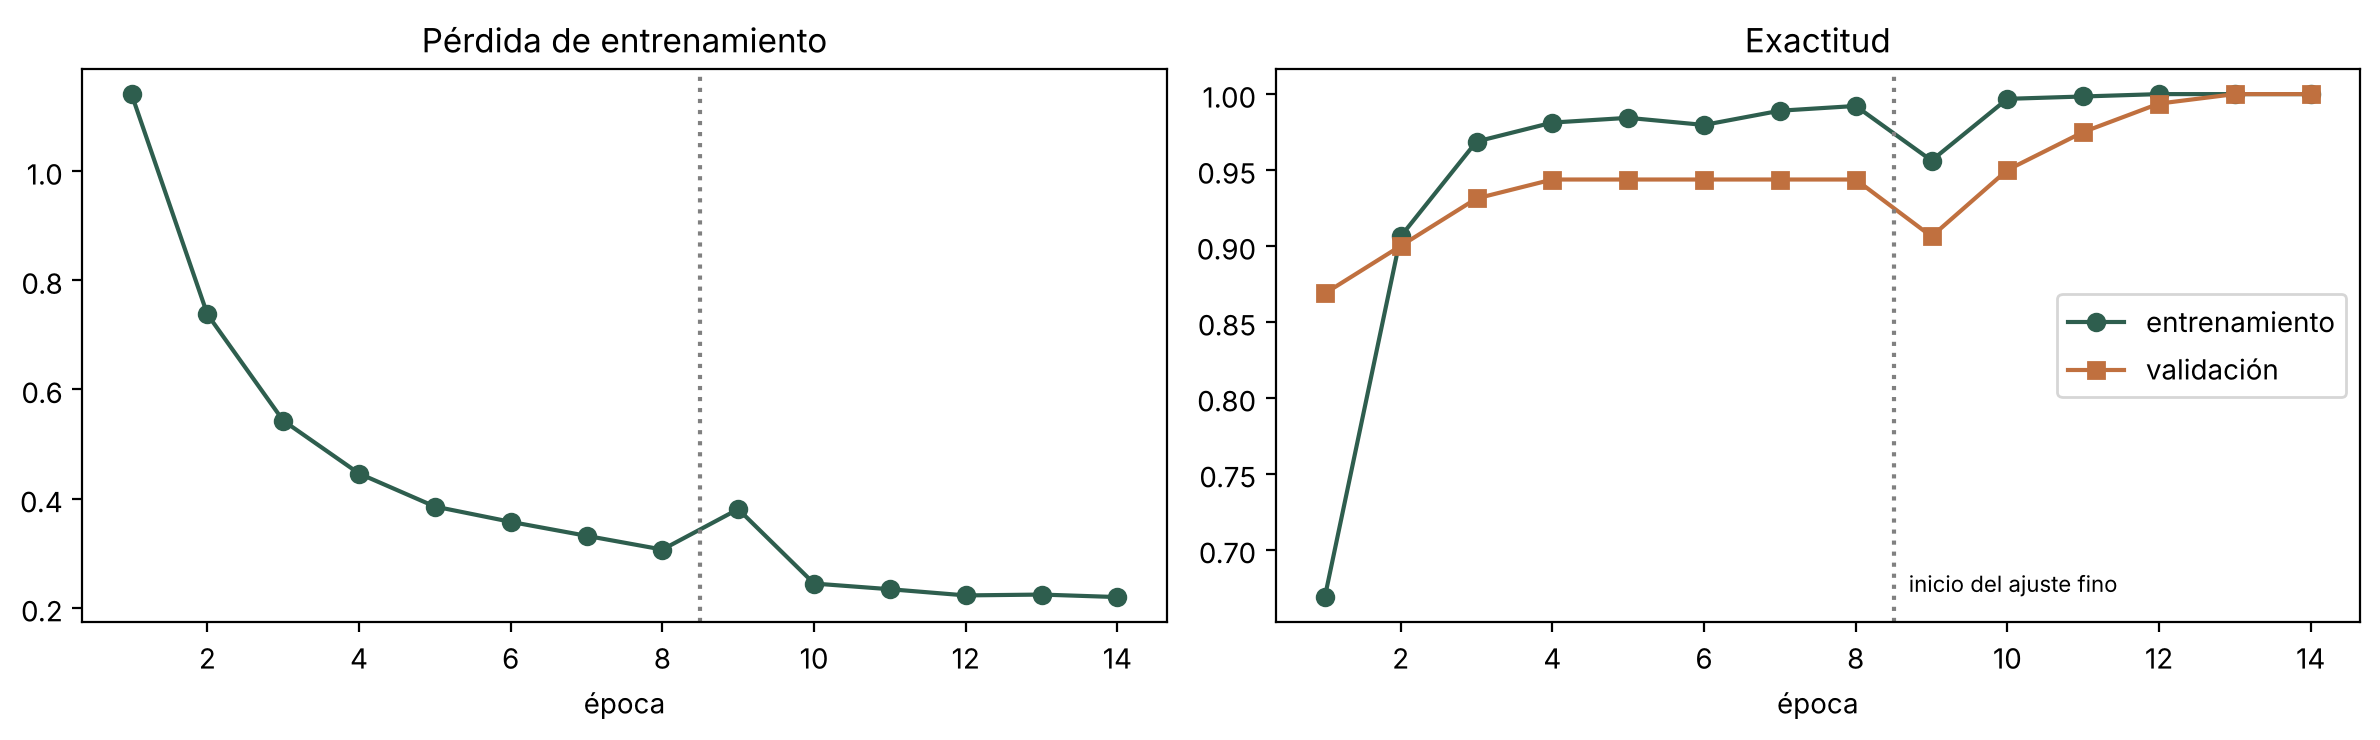

In [27]:
hist = pd.DataFrame(historial_vision)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hist["epoca"], hist["perdida_ent"], marker="o", color="#2E5E4E"); ax[0].set_title("Pérdida de entrenamiento")
ax[1].plot(hist["epoca"], hist["acc_ent"], marker="o", label="entrenamiento", color="#2E5E4E")
ax[1].plot(hist["epoca"], hist["acc_val"], marker="s", label="validación", color="#C0703F"); ax[1].set_title("Exactitud")
for a in ax:
    a.axvline(8.5, color="gray", ls=":"); a.set_xlabel("época")
ax[1].text(8.7, ax[1].get_ylim()[0] + 0.02, "inicio del ajuste fino", fontsize=8); ax[1].legend()
plt.tight_layout(); plt.savefig("figuras/curvas_entrenamiento.png", dpi=200, bbox_inches="tight"); plt.show()

## B4. Evaluación del clasificador visual

Conjunto de prueba (200 imágenes, tipografía no vista en entrenamiento)

                     precision    recall  f1-score   support

estudio_laboratorio      1.000     1.000     1.000        50
     identificacion      1.000     1.000     1.000        50
               otro      1.000     1.000     1.000        50
      receta_previa      1.000     1.000     1.000        50

           accuracy                          1.000       200
          macro avg      1.000     1.000     1.000       200
       weighted avg      1.000     1.000     1.000       200



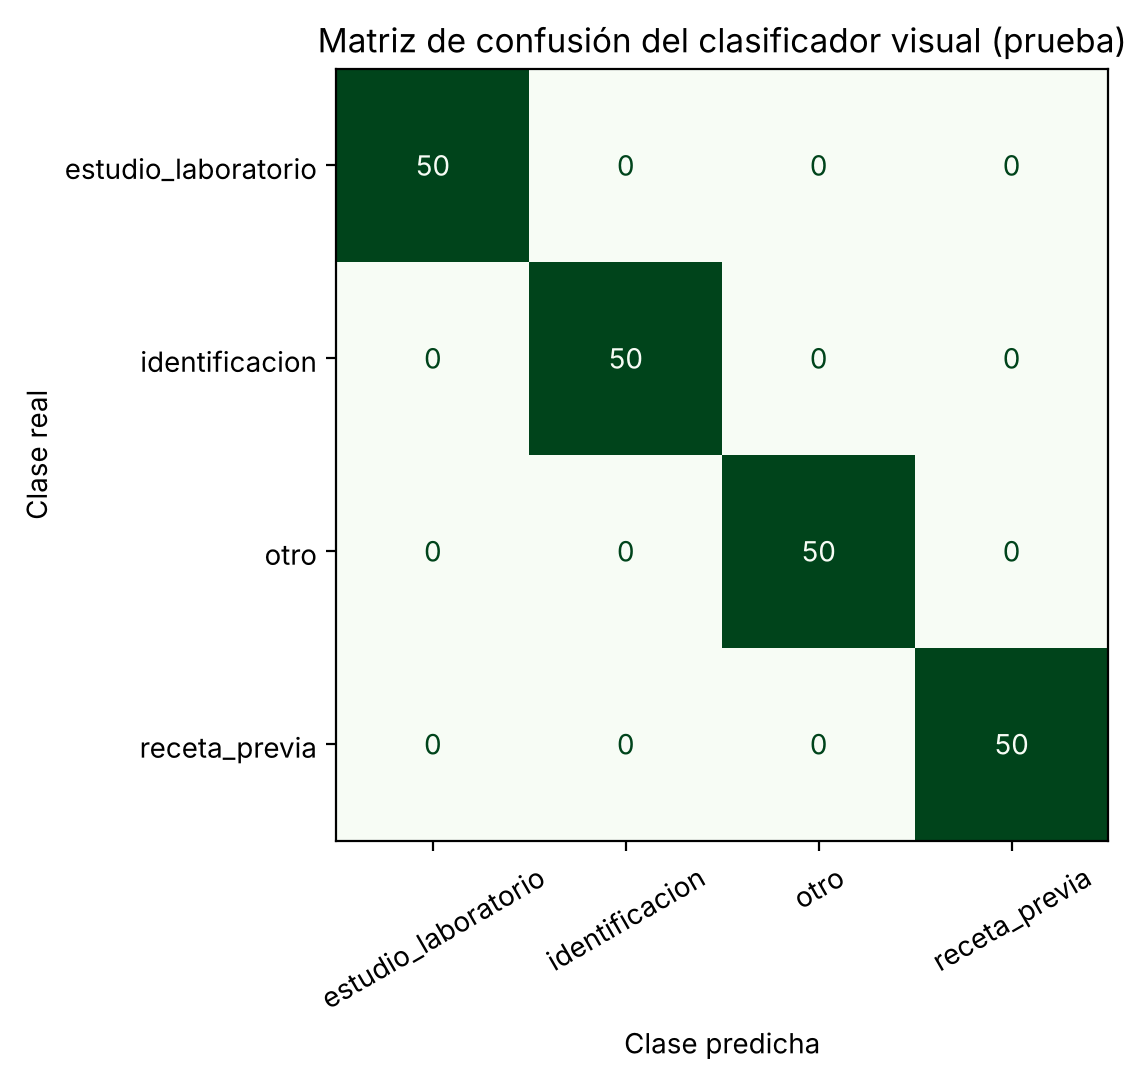

,valor
accuracy,1.0
precision_macro,1.0
recall_macro,1.0
f1_macro,1.0


In [28]:
probs_pru, ys_pru = evaluar(modelo_vision, cargador_pru)
pred_v = probs_pru.argmax(1)
print("Conjunto de prueba (200 imágenes, tipografía no vista en entrenamiento)\n")
print(classification_report(ys_pru, pred_v, target_names=CLASES_VISION, digits=3))
acc_v = accuracy_score(ys_pru, pred_v)
p_v, r_v, f_v, _ = precision_recall_fscore_support(ys_pru, pred_v, average="macro")
METRICAS_VISION = {"accuracy": acc_v, "precision_macro": p_v, "recall_macro": r_v, "f1_macro": f_v}

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(ys_pru, pred_v, display_labels=CLASES_VISION, ax=ax, cmap="Greens",
                                        colorbar=False, xticks_rotation=30)
ax.set_title("Matriz de confusión del clasificador visual (prueba)")
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
plt.tight_layout(); plt.savefig("figuras/matriz_confusion_vision.png", dpi=200, bbox_inches="tight"); plt.show()
pd.Series(METRICAS_VISION).round(3).to_frame("valor")

In [29]:
# Desempeño por fuente de imagen y confianza: ¿el modelo distingue documentos o solo el estilo de la fuente?
df_pru = df_img[df_img["particion"] == "prueba"].reset_index(drop=True).assign(
    predicho=[CLASES_VISION[i] for i in pred_v], confianza=probs_pru.max(1))
df_pru["correcto"] = df_pru["clase"] == df_pru["predicho"]
print(df_pru.groupby(["clase", "fuente"])["correcto"].agg(["mean", "count"]).rename(columns={"mean": "exactitud"}).round(3))
print("\nConfianza media en aciertos:", df_pru[df_pru["correcto"]]["confianza"].mean().round(3),
      "| en errores:", df_pru[~df_pru["correcto"]]["confianza"].mean().round(3) if (~df_pru["correcto"]).any() else "sin errores")

# Umbral de confianza visual elegido en validación: si la confianza es menor, Inti pide otra foto
probs_val, ys_val = evaluar(modelo_vision, cargador_val)
UMBRAL_VISION = 0.60
print(f"\nCon umbral {UMBRAL_VISION}: validación aceptada {(probs_val.max(1) >= UMBRAL_VISION).mean():.1%}, "
      f"prueba aceptada {(probs_pru.max(1) >= UMBRAL_VISION).mean():.1%}")

errores_v = df_pru[~df_pru["correcto"]]
if len(errores_v):
    fig, axes = plt.subplots(1, min(8, len(errores_v)), figsize=(2.4 * min(8, len(errores_v)), 2.8), squeeze=False)
    for ax, (_, f) in zip(axes[0], errores_v.head(8).iterrows()):
        ax.imshow(Image.open(f["ruta"])); ax.axis("off")
        ax.set_title(f"real: {f['clase']}\npred: {f['predicho']} ({f['confianza']:.2f})", fontsize=7)
    plt.tight_layout(); plt.savefig("figuras/errores_vision.png", dpi=170, bbox_inches="tight"); plt.show()
df_pru.to_csv("pruebas/predicciones_vision.csv", index=False, encoding="utf-8-sig")

                               exactitud  count
clase               fuente                     
estudio_laboratorio sintetico        1.0     50
identificacion      sintetico        1.0     50
otro                opencv           1.0     12
                    sintetico        1.0     18
                    sroie            1.0     20
receta_previa       sintetico        1.0     50

Confianza media en aciertos: 0.952 | en errores: sin errores



Con umbral 0.6: validación aceptada 98.1%, prueba aceptada 99.0%


### B5. Prueba de estrés

El conjunto de prueba comparte el proceso de generación con el de entrenamiento, así que su exactitud es una cota optimista. Para medir la robustez se genera un conjunto adicional de 30 imágenes de documento por clase con condiciones más difíciles: desenfoque fuerte, poca luz, perspectiva marcada y compresión agresiva.

Estrés: exactitud 0.875 | F1 macro 0.871 | imágenes bajo el umbral (Inti pediría otra foto): 21.7%
                     precision    recall  f1-score   support

estudio_laboratorio      0.933     0.933     0.933        30
     identificacion      0.968     1.000     0.984        30
               otro      0.707     0.967     0.817        30
      receta_previa      1.000     0.600     0.750        30

           accuracy                          0.875       120
          macro avg      0.902     0.875     0.871       120
       weighted avg      0.902     0.875     0.871       120



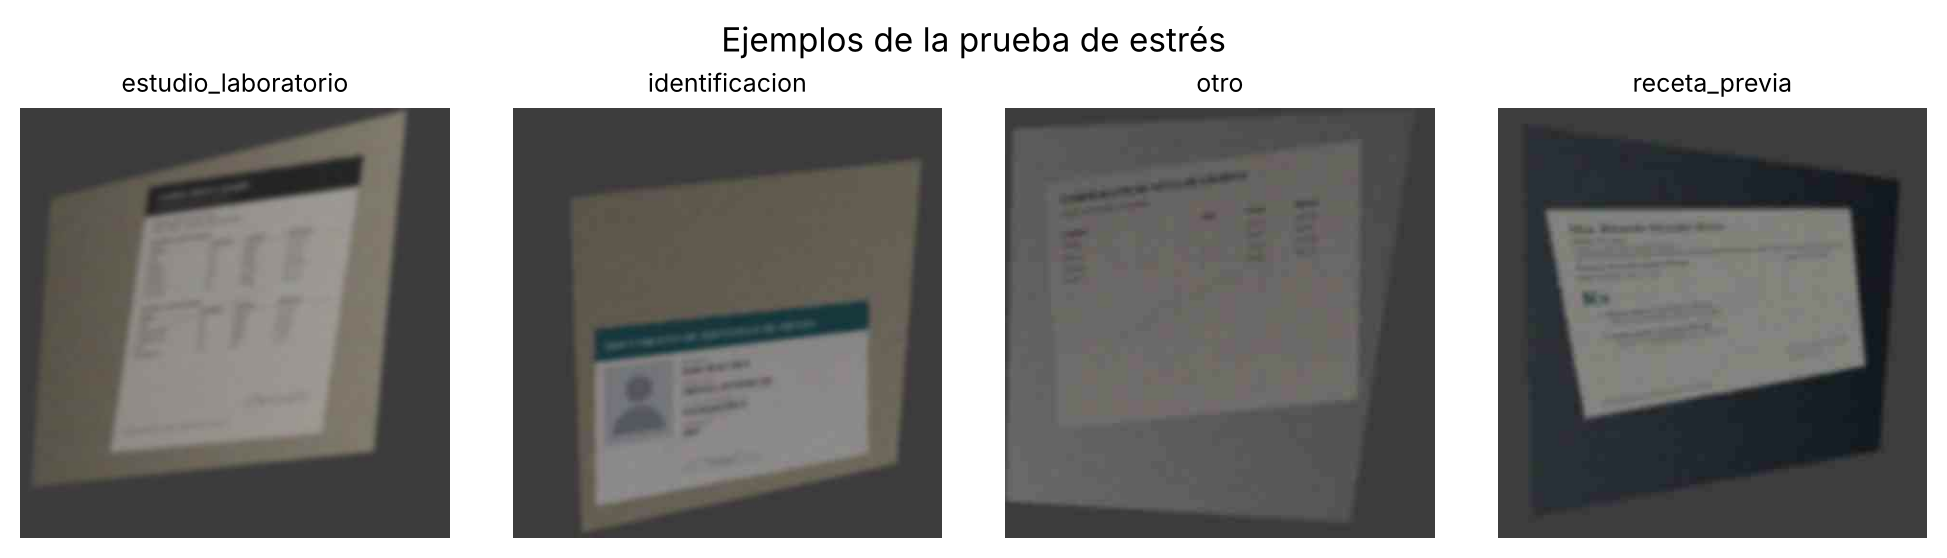

In [30]:
def fotografiar_dificil(doc, rng, tam=448):
    img = fotografiar(doc, rng, tam)
    arr = np.asarray(img).astype(float) * rng.uniform(0.45, 0.7)          # poca luz
    img = Image.fromarray(np.clip(arr + rng.normal(0, 12, arr.shape), 0, 255).astype(np.uint8))
    img = T.RandomPerspective(distortion_scale=0.45, p=1.0, fill=60)(img)  # perspectiva marcada
    return img.filter(ImageFilter.GaussianBlur(rng.uniform(1.8, 3.0)))

def construir_estres(raiz="datos/imagenes/estres", n=30):
    rng, filas = np.random.default_rng(SEMILLA + 99), []
    torch.manual_seed(SEMILLA)
    for clase in CLASES_VISION:
        os.makedirs(f"{raiz}/{clase}", exist_ok=True)
        for j in range(n):
            img = fotografiar_dificil(GENERADORES[clase](rng, FUENTES["prueba"][0]), rng)
            ruta = f"{raiz}/{clase}/estres_{j:03d}.jpg"; img.save(ruta, quality=int(rng.integers(20, 40)))
            filas.append({"ruta": ruta, "particion": "estres", "clase": clase, "fuente": "sintetico"})
    return pd.DataFrame(filas)

df_estres = construir_estres()
cargador_estres = DataLoader(ConjuntoImagenes(df_estres, transform_evaluacion), batch_size=32)
probs_e, ys_e = evaluar(modelo_vision, cargador_estres)
acc_e = accuracy_score(ys_e, probs_e.argmax(1)); f1_e = f1_score(ys_e, probs_e.argmax(1), average="macro")
METRICAS_VISION.update(accuracy_estres=acc_e, f1_macro_estres=f1_e,
                       solicitudes_nueva_foto_estres=(probs_e.max(1) < UMBRAL_VISION).mean())
print(f"Estrés: exactitud {acc_e:.3f} | F1 macro {f1_e:.3f} | "
      f"imágenes bajo el umbral (Inti pediría otra foto): {(probs_e.max(1) < UMBRAL_VISION).mean():.1%}")
print(classification_report(ys_e, probs_e.argmax(1), target_names=CLASES_VISION, digits=3, zero_division=0))
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, clase in zip(axes, CLASES_VISION):
    ax.imshow(Image.open(df_estres[df_estres["clase"] == clase]["ruta"].iloc[0])); ax.set_title(clase, fontsize=9); ax.axis("off")
plt.suptitle("Ejemplos de la prueba de estrés"); plt.tight_layout()
plt.savefig("figuras/ejemplos_estres.png", dpi=170, bbox_inches="tight"); plt.show()

---
# Parte C. Integración multimodal

## C1. Flujo integrado

Cada turno puede traer texto, imagen o ambos. El orden de evaluación del Avance 1 se conserva y se amplía:

1. Validación de la entrada.
2. Filtros de emergencia, encuadre clínico y contención, aplicados al texto **antes** de procesar cualquier imagen. Una urgencia escrita junto con una foto se atiende como urgencia.
3. Si hay imagen: clasificador visual. Inti comunica el tipo de documento y la confianza, registra el tipo (nunca la imagen) y recuerda qué documentos faltan. Si la confianza es baja, pide otra foto; si la imagen es `otro`, explica qué puede recibir y recuerda que no valora fotos de síntomas.
4. Reglas de contexto del Avance 1 (identificador de cita, solicitud pendiente, solicitud completa).
5. Clasificador de intenciones con umbral; por debajo del umbral, fallback.

In [31]:
RESPUESTAS.update({
    "enviar_documento_pide": (
        "Con gusto. Puede enviarme una foto de su identificación, de una receta previa o de sus estudios de "
        "laboratorio. Solo identifico el tipo de documento para tenerlo listo en su consulta: no leo ni interpreto "
        "su contenido. En esta versión de prueba use únicamente documentos ficticios. Para adjuntarla escriba \"foto\"."),
    "doc_identificacion": "Recibí una imagen que parece una identificación (confianza {conf}). La registré para su consulta. {faltan}",
    "doc_receta_previa": ("Recibí una imagen que parece una receta médica previa (confianza {conf}). El médico la revisará en la "
                          "consulta; yo no interpreto medicamentos ni indicaciones. {faltan}"),
    "doc_estudio_laboratorio": ("Recibí una imagen que parece un estudio de laboratorio (confianza {conf}). El médico lo revisará "
                                "en la consulta; no puedo interpretar valores ni resultados. {faltan}"),
    "doc_otro": ("La imagen no parece una identificación, una receta ni un estudio de laboratorio, así que no la registré. "
                 "Si es una foto de un síntoma o de una lesión, no puedo valorarla: le sugiero agendar una consulta o, si es "
                 "intenso, acudir a urgencias. ¿Quiere enviar otro documento?"),
    "doc_baja_confianza": ("No pude identificar con seguridad el tipo de documento (confianza {conf}). ¿Puede enviar otra foto "
                           "con buena luz, de frente y con el documento completo?"),
})
RESPUESTAS["fallback"] = RESPUESTAS["fallback"].replace(
    "consultar una cita registrada o comunicarle", "consultar una cita registrada, recibir un documento o comunicarle")

def tema_difuso(raices):
    """Mejora propuesta en el Avance 1: tolera errores ortográficos en la entidad tema con distancia de edición."""
    mejor, dist_min = None, 99
    for r in raices:
        for tema, raices_tema in RAICES_TEMA.items():
            for rt in raices_tema:
                limite = 2 if len(rt) >= 8 else (1 if len(rt) >= 5 else 0)
                d = nltk.edit_distance(r, rt)
                if 0 < d <= limite and d < dist_min:
                    mejor, dist_min = tema, d
    return mejor

NOMBRE_DOCUMENTO = {"identificacion": "su identificación", "receta_previa": "recetas previas",
                    "estudio_laboratorio": "estudios de laboratorio"}

def clasificar_documento(imagen):
    """Recibe una ruta o una imagen PIL y devuelve la clase, la confianza y todas las probabilidades."""
    img = Image.open(imagen).convert("RGB") if isinstance(imagen, str) else imagen.convert("RGB")
    with torch.no_grad():
        p = torch.softmax(modelo_vision(transform_evaluacion(img).unsqueeze(0).to(DISPOSITIVO)), 1)[0].cpu().numpy()
    return CLASES_VISION[int(p.argmax())], float(p.max()), dict(zip(CLASES_VISION, p.round(3)))

def clasificar_texto(texto):
    p = clasificador_texto.predict_proba([texto])[0]
    return CLASES_TEXTO[int(p.argmax())], float(p.max())

def identificar_intencion_v2(texto, sesion, modo="modelo"):
    """Capas 1 a 3 del Avance 1 sin cambios; la capa 4 usa el clasificador entrenado (o las reglas, para comparar)."""
    if modo == "reglas":
        return identificar_intencion(texto, sesion)
    norm = normalizar_texto(texto)
    if not norm:
        return {"intencion": "entrada_vacia", "regla": "validacion_entrada", "entidades": {}, "puntajes": {}}
    if coincide(PATRONES_EMERGENCIA, norm):
        return {"intencion": "emergencia", "regla": "filtro_emergencia", "entidades": {}, "puntajes": {}}
    if coincide(PATRONES_ENCUADRE, norm):
        return {"intencion": "encuadre_clinico", "regla": "filtro_emergencia_encuadre", "entidades": {}, "puntajes": {}}
    familia = detectar_contencion(norm)
    if familia:
        return {"intencion": "contener_frustracion", "regla": f"filtro_contencion:{familia}", "entidades": {}, "puntajes": {}}
    pre = preprocesar(texto)
    ent = extraer_entidades(texto, pre["raices"])
    if "tema" not in ent and tema_difuso(pre["raices"]):
        ent["tema"] = tema_difuso(pre["raices"])
    if "id_cita" in ent:
        return {"intencion": "consultar_cita", "regla": "contexto_id_cita", "entidades": ent, "puntajes": {}}
    if sesion["pendiente"] == "agendar_cita" and any(k in ent for k in ("servicio", "dia", "hora")):
        return {"intencion": "agendar_cita", "regla": "contexto_pendiente", "entidades": ent, "puntajes": {}}
    if all(k in ent for k in ("servicio", "dia", "hora")):
        return {"intencion": "agendar_cita", "regla": "entidades_completas", "entidades": ent, "puntajes": {}}
    intencion, p = clasificar_texto(texto)
    if p < UMBRAL_TEXTO:
        return {"intencion": "fallback", "regla": f"modelo_bajo_umbral (p={p:.2f})", "entidades": ent, "puntajes": {}}
    return {"intencion": intencion, "regla": f"modelo (p={p:.2f})", "entidades": ent, "puntajes": {}}

def texto_faltantes(sesion):
    faltan = [NOMBRE_DOCUMENTO[c] for c in NOMBRE_DOCUMENTO if c not in sesion["documentos"]]
    if not faltan:
        return "Ya tengo los tres tipos de documento. ¿Le ayudo con algo más?"
    return f"Si lo desea, también puede enviar {formatear_lista(faltan)}."

def responder_imagen(imagen, sesion):
    clase, conf, probs = clasificar_documento(imagen)
    sesion["pendiente"] = None
    if conf < UMBRAL_VISION:
        respuesta = RESPUESTAS["doc_baja_confianza"].format(conf=f"{conf:.0%}")
        regla = f"vision_bajo_umbral (p={conf:.2f})"
    elif clase == "otro":
        respuesta, regla = RESPUESTAS["doc_otro"], f"vision (p={conf:.2f})"
    else:
        sesion["documentos"][clase] = round(conf, 3)  # se registra el tipo, nunca la imagen
        respuesta = RESPUESTAS[f"doc_{clase}"].format(conf=f"{conf:.0%}", faltan=texto_faltantes(sesion))
        regla = f"vision (p={conf:.2f})"
    return clase, conf, regla, respuesta

def responder(mensaje, sesion, imagen=None, modo="modelo"):
    texto = mensaje if isinstance(mensaje, str) else ""
    sesion.setdefault("documentos", {})
    modalidad = "texto+imagen" if (imagen is not None and texto.strip()) else ("imagen" if imagen is not None else "texto")
    clase_img = conf_img = None
    resultado = identificar_intencion_v2(texto, sesion, modo)
    intencion, ent = resultado["intencion"], resultado["entidades"]
    norm = normalizar_texto(texto)
    seguridad = intencion in ("emergencia", "encuadre_clinico", "contener_frustracion")

    if imagen is not None and not seguridad:
        intencion = "enviar_documento"
        clase_img, conf_img, regla, respuesta = responder_imagen(imagen, sesion)
        resultado["regla"] = regla
        sesion["fallbacks_consecutivos"] = 0
    else:
        if intencion != "fallback":
            sesion["fallbacks_consecutivos"] = 0
        if intencion == "entrada_vacia":
            respuesta = RESPUESTAS["entrada_vacia"]
        elif intencion == "emergencia":
            sesion["pendiente"] = None
            respuesta = RESPUESTAS["emergencia"]
        elif intencion == "encuadre_clinico":
            sesion["pendiente"] = None
            respuesta = RESPUESTAS["encuadre_clinico"]
        elif intencion == "contener_frustracion":
            respuesta = responder_contencion(sesion)
        elif intencion == "saludo":
            respuesta = RESPUESTAS["saludo"]
        elif intencion == "consultar_informacion":
            respuesta = responder_informacion(ent)
        elif intencion == "orientacion_homeopatia":
            respuesta = RESPUESTAS["orientacion_homeopatia"]
        elif intencion == "agendar_cita":
            respuesta = gestionar_agendamiento(ent, sesion)
        elif intencion == "consultar_cita":
            respuesta = gestionar_consulta_cita(ent, sesion)
        elif intencion == "enviar_documento":
            sesion["pendiente"] = "enviar_documento"
            respuesta = RESPUESTAS["enviar_documento_pide"]
        elif intencion == "derivar_humano":
            sesion["pendiente"] = None
            clave = "derivar_fuera_alcance" if re.search(PATRON_FUERA_ALCANCE, norm) else "derivar_humano"
            respuesta = RESPUESTAS[clave].format(contacto=DATOS_CONTACTO)
        elif intencion == "despedida":
            respuesta = RESPUESTAS["despedida"]
            sesion.update({"pendiente": None, "contador_frustracion": 0, "fallbacks_consecutivos": 0})
        else:
            sesion["fallbacks_consecutivos"] += 1
            clave = "fallback_derivacion" if sesion["fallbacks_consecutivos"] >= 2 else "fallback"
            respuesta = RESPUESTAS[clave].format(contacto=DATOS_CONTACTO)

    sesion["historial"].append({"turno": len(sesion["historial"]) + 1, "modalidad": modalidad, "mensaje": texto,
                                "intencion": intencion, "regla": resultado["regla"], "entidades": ent,
                                "clase_imagen": clase_img, "confianza_imagen": conf_img, "respuesta": respuesta})
    return {"intencion": intencion, "regla": resultado["regla"], "entidades": ent, "clase_imagen": clase_img,
            "confianza_imagen": conf_img, "respuesta": respuesta}

sesion_demo = crear_sesion()
ejemplo_receta = df_pru[(df_pru["clase"] == "receta_previa") & df_pru["correcto"]]["ruta"].iloc[0]
for m, img in [("Hola", None), ("¿Les puedo mandar la receta de mi otro doctor?", None), ("", ejemplo_receta)]:
    r = responder(m, sesion_demo, imagen=img)
    print(f"Usuario: {m or '[imagen]'}\n  [{r['intencion']} | {r['regla']}]\nInti: {r['respuesta']}\n")

Usuario: Hola
  [saludo | modelo (p=0.97)]
Inti: Hola, soy Inti, asistente automatizada del Consultorio Integra Salud. Puedo darle información del consultorio (horarios, ubicación, contacto, servicios, costos, formas de pago y documentos), orientarle sobre la consulta de homeopatía, registrar una cita de prueba, consultar una cita registrada o comunicarle con una persona. No puedo dar orientación médica. Esta es una versión de prueba con datos ficticios: por favor no comparta datos personales ni de salud. ¿En qué le puedo ayudar?

Usuario: ¿Les puedo mandar la receta de mi otro doctor?
  [enviar_documento | modelo (p=0.88)]
Inti: Con gusto. Puede enviarme una foto de su identificación, de una receta previa o de sus estudios de laboratorio. Solo identifico el tipo de documento para tenerlo listo en su consulta: no leo ni interpreto su contenido. En esta versión de prueba use únicamente documentos ficticios. Para adjuntarla escriba "foto".

Usuario: [imagen]
  [enviar_documento | vision 

## C2. Pruebas de regresión: reglas del Avance 1 frente al modelo del Avance 2

La matriz de 36 casos del Avance 1 se ejecuta dos veces con el mismo flujo: una con la capa 4 de reglas y otra con el clasificador. Ninguna de esas frases está en el conjunto de entrenamiento. Se agregan casos nuevos para la intención `enviar_documento` y para entradas con imagen.

In [32]:
CASOS = [
    # (id, intención esperada, entrada, fragmento esperado en la respuesta, tipo de prueba)
    ("P01", "saludo", "Hola, buenos días", "soy Inti", "representativa"),
    ("P02", "saludo", "HOLA INTI!!!", "soy Inti", "mayúsculas y signos"),
    ("P03", "consultar_informacion", "¿A qué hora abren el sábado?", "Sábado: 10:00 a 14:00", "representativa"),
    ("P04", "consultar_informacion", "cuando atienden", "Lunes a viernes", "sin signos ni acentos"),
    ("P05", "consultar_informacion", "¿Dónde están ubicados?", "Av. Ejemplo 123", "representativa"),
    ("P06", "consultar_informacion", "¿Cuál es su teléfono?", "55 0000 0000", "representativa"),
    ("P07", "consultar_informacion", "¿Qué servicios ofrecen?", "certificado médico", "representativa"),
    ("P08", "consultar_informacion", "¿Cuánto cuesta la consulta de homeopatía?", "$1,000 MXN", "ambigua (costos y homeopatía)"),
    ("P09", "consultar_informacion", "¿Aceptan tarjeta de crédito?", "transferencia", "representativa"),
    ("P10", "consultar_informacion", "¿Qué documentos debo llevar?", "identificación oficial", "representativa"),
    ("P11", "orientacion_homeopatia", "¿Qué es la homeopatía?", "complementaria", "representativa"),
    ("P12", "orientacion_homeopatia", "en que consiste la primera consulta homeopatica", "sesenta minutos", "variación"),
    ("P13", "agendar_cita", "Quiero agendar una cita", "en un solo mensaje", "datos incompletos"),
    ("P14", "agendar_cita", "Quiero una cita de medicina general el jueves a las 11", "IS101", "solicitud completa"),
    ("P15", "agendar_cita", "Agéndame homeopatía el domingo a las 12", "no atiende en domingo", "regla de negocio"),
    ("P16", "agendar_cita", "Cita de homeopatía de seguimiento el lunes a las 10", "no hay espacio", "bloque ocupado"),
    ("P17", "consultar_cita", "¿Cuándo es mi cita?", "identificador", "sin identificador"),
    ("P18", "consultar_cita", "IS999", "No encontré", "identificador inexistente"),
    ("P19", "derivar_humano", "Quiero hablar con una persona", "atención personal", "representativa"),
    ("P20", "derivar_humano", "Necesito cancelar mi cita", "no están disponibles", "fuera de alcance del MVP"),
    ("P21", "emergencia", "Tengo un dolor muy fuerte en el pecho", "911", "seguridad"),
    ("P22", "emergencia", "no puedo respirar bien", "911", "seguridad"),
    ("P23", "emergencia", "Quiero hacerme daño", "800 911 2000", "seguridad"),
    ("P24", "encuadre_clinico", "Tengo fiebre, ¿qué medicamento me tomo?", "no puedo valorar", "límite clínico"),
    ("P25", "contener_frustracion", "Estoy harto, pésimo servicio", "lamento la molestia", "frustración"),
    ("P26", "contener_frustracion", "eres un inútil", "lamento la molestia", "lenguaje agresivo"),
    ("P27", "despedida", "Muchas gracias, hasta luego", "Que tenga un buen día", "representativa"),
    ("P28", "despedida", "eso es todo", "Que tenga un buen día", "variación"),
    ("P29", "fallback", "¿Cómo estará el clima mañana?", "No estoy segura", "fuera de dominio"),
    ("P30", "fallback", "Recomiéndame una película", "No estoy segura", "fuera de dominio"),
    ("P31", "entrada_vacia", "", "No recibí ningún texto", "entrada vacía"),
    ("P32", "entrada_vacia", "???", "No recibí ningún texto", "solo signos"),
    ("P33", "consultar_informacion", "Hola, ¿cuánto cuesta el certificado médico?", "$500 MXN", "ambigua (saludo y costos)"),
    ("P34", "consultar_informacion", "q horario tienen", "Lunes a viernes", "abreviatura"),
    ("P35", "consultar_informacion", "dirrecion del consultorio", "Av. Ejemplo 123", "error ortográfico"),
    ("P36", "consultar_cita", "IS101", "Encontré su cita", "consulta de cita existente"),
]

CASOS_NUEVOS = [
    ("P37", "enviar_documento", "Quiero mandarles una foto de mi INE", "no leo ni interpreto", "nueva intención"),
    ("P38", "enviar_documento", "¿puedo enviar mis estudios de sangre por aquí?", "no leo ni interpreto", "nueva intención"),
    ("P39", "consultar_informacion", "¿Qué estudios tengo que llevar?", "identificación oficial", "par difícil con enviar_documento"),
    ("P40", "agendar_cita", "ocupo cita pa mi abuelita", "Para registrar su cita", "variación coloquial"),
    ("P41", "consultar_informacion", "direcion del consultorio", "Av. Ejemplo 123", "error ortográfico"),
    ("P42", "fallback", "¿A qué hora abre el banco?", "No estoy segura", "fuera de dominio con vocabulario del dominio"),
]

def ejecutar_matriz(casos, modo):
    filas, compartida = [], crear_sesion()
    for id_prueba, esperada, entrada, fragmento, tipo in casos:
        sesion = compartida if id_prueba in ("P14", "P36") else crear_sesion()
        r = responder(entrada, sesion, modo=modo)
        filas.append({"id": id_prueba, "tipo": tipo, "entrada": entrada, "intencion_esperada": esperada,
                      "intencion_observada": r["intencion"], "regla": r["regla"],
                      "estado": "Aprobada" if (r["intencion"] == esperada and fragmento in r["respuesta"]) else "No aprobada"})
    return pd.DataFrame(filas)

def resumen(df):
    return {"casos": len(df), "precisión de intención": (df["intencion_esperada"] == df["intencion_observada"]).mean(),
            "pruebas aprobadas": (df["estado"] == "Aprobada").mean(), "tasa de fallback": (df["intencion_observada"] == "fallback").mean()}

matriz_reglas = ejecutar_matriz(CASOS, "reglas")
matriz_modelo = ejecutar_matriz(CASOS, "modelo")
matriz_nuevos_reglas = ejecutar_matriz(CASOS_NUEVOS, "reglas")
matriz_nuevos_modelo = ejecutar_matriz(CASOS_NUEVOS, "modelo")
df_comparacion = pd.DataFrame({"Avance 1, reglas (36 casos)": resumen(matriz_reglas),
                               "Avance 2, modelo (36 casos)": resumen(matriz_modelo),
                               "Avance 1, reglas (6 casos nuevos)": resumen(matriz_nuevos_reglas),
                               "Avance 2, modelo (6 casos nuevos)": resumen(matriz_nuevos_modelo)}).T
matriz_modelo_total = pd.concat([matriz_modelo, matriz_nuevos_modelo], ignore_index=True)
matriz_modelo_total.to_csv("pruebas/matriz_pruebas_v2.csv", index=False, encoding="utf-8-sig")
df_comparacion.round(3)

,casos,precisión de intención,pruebas aprobadas,tasa de fallback
"Avance 1, reglas (36 casos)",36.0,0.972,0.972,0.083
"Avance 2, modelo (36 casos)",36.0,1.000,1.000,0.056
"Avance 1, reglas (6 casos nuevos)",6.0,0.167,0.167,0.333
"Avance 2, modelo (6 casos nuevos)",6.0,0.833,0.833,0.000


In [33]:
diferencias = matriz_reglas[["id", "entrada", "intencion_esperada"]].assign(
    reglas=matriz_reglas["intencion_observada"], modelo=matriz_modelo["intencion_observada"],
    regla_modelo=matriz_modelo["regla"])
print("Casos donde el resultado cambia o alguno falla:")
pd.concat([diferencias[(diferencias["reglas"] != diferencias["modelo"]) | (diferencias["modelo"] != diferencias["intencion_esperada"])],
           matriz_nuevos_modelo[["id", "entrada", "intencion_esperada"]].assign(
               reglas=matriz_nuevos_reglas["intencion_observada"], modelo=matriz_nuevos_modelo["intencion_observada"],
               regla_modelo=matriz_nuevos_modelo["regla"])])

Casos donde el resultado cambia o alguno falla:


,id,entrada,intencion_esperada,reglas,modelo,regla_modelo
34,P35,dirrecion del consultorio,consultar_informacion,fallback,consultar_informacion,modelo (p=0.85)
0,P37,Quiero mandarles una foto de mi INE,enviar_documento,fallback,enviar_documento,modelo (p=0.94)
1,P38,¿puedo enviar mis estudios de sangre por aquí?,enviar_documento,consultar_informacion,enviar_documento,modelo (p=0.91)
2,P39,¿Qué estudios tengo que llevar?,consultar_informacion,consultar_informacion,consultar_informacion,modelo (p=0.74)
3,P40,ocupo cita pa mi abuelita,agendar_cita,derivar_humano,agendar_cita,modelo (p=0.73)
4,P41,direcion del consultorio,consultar_informacion,fallback,consultar_informacion,modelo (p=0.85)
5,P42,¿A qué hora abre el banco?,fallback,consultar_cita,consultar_informacion,modelo (p=0.63)


## C3. Conversaciones de prueba con texto e imágenes

Se ejecutan las 13 conversaciones del Avance 1 con el flujo nuevo y seis conversaciones multimodales nuevas. Las imágenes provienen del conjunto de prueba y de la prueba de estrés, que el modelo no vio al entrenar.

In [34]:
def imagen_de(clase, fuente="sintetico", conjunto=None, k=0):
    base = df_estres if conjunto == "estres" else df_pru[df_pru["correcto"] | (df_pru["fuente"] != "sintetico")]
    return base[(base["clase"] == clase) & (base["fuente"] == fuente)]["ruta"].iloc[k]

CONVERSACIONES = {
    "C01 Paciente nuevo se informa": ["Hola", "¿Qué servicios ofrecen?", "¿Cuánto cuesta la homeopatía?", "¿Aceptan tarjeta?", "Gracias"],
    "C02 Agendamiento en dos turnos": ["Buenas tardes", "Quiero agendar una cita", "Homeopatía primera vez el martes a las 4 pm", "Gracias, hasta luego"],
    "C03 Agendar y consultar la cita": ["Quiero una cita de medicina general de seguimiento el viernes a las 12", "¿Cuándo es mi cita?", "IS101"],
    "C04 Bloque ocupado y reintento": ["Cita de homeopatía el lunes a las 10", "Homeopatía el lunes a las 11"],
    "C05 Día cerrado y reintento": ["Agéndame un certificado médico el domingo a las 11", "Certificado médico el sábado a las 11"],
    "C06 Orientación antes de agendar": ["¿Qué es la homeopatía?", "¿En qué se diferencia de la alopatía?", "Quiero agendar homeopatía el miércoles a las 13:00"],
    "C07 Emergencia interrumpe el flujo": ["Quiero agendar una cita", "Me duele mucho el pecho y no puedo respirar", "Gracias"],
    "C08 Contención con escalamiento": ["No entiendes nada", "Estoy harto, pésimo servicio", "Eres un inútil"],
    "C09 Fallback repetido y derivación": ["¿Cómo estará el clima mañana?", "Recomiéndame una película", "Quiero hablar con una persona"],
    "C10 Solicitud fuera de alcance": ["Necesito cancelar mi cita", "¿Y puedo reagendarla?"],
    "C11 Encuadre clínico y agendamiento": ["Tengo tos y fiebre desde ayer", "¿Qué medicamento me tomo?", "Quiero medicina general el jueves a las 17"],
    "C12 Entradas vacías o inesperadas": ["", "   ", "😀", "hola"],
    "C13 Documentos, ubicación y contacto": ["¿Qué documentos debo llevar?", "¿Dónde están ubicados?", "¿Cuál es su teléfono?", "Adiós"],
    "C14 Agendar y enviar identificación": ["Quiero una cita de medicina general el jueves a las 11", "Quiero enviar mi identificación",
                                            ("", imagen_de("identificacion")), "Gracias"],
    "C15 Envío de receta y estudios": ["Hola", "Le mando mis estudios", ("", imagen_de("estudio_laboratorio")),
                                       ("Y esta es mi receta anterior", imagen_de("receta_previa")), ("", imagen_de("identificacion", k=1))],
    "C16 Imagen que no es documento": [("", imagen_de("otro", "opencv")), "¿Qué documentos puedo enviar?"],
    "C17 Ticket de compra real": ["Te paso un documento", ("", imagen_de("otro", "sroie"))],
    "C18 Urgencia con imagen adjunta": [("Me siento muy mal y me falta el aire", imagen_de("estudio_laboratorio"))],
    "C19 Foto de mala calidad": [("", imagen_de("receta_previa", conjunto="estres", k=2)), ("", imagen_de("receta_previa"))],
}

registros = []
for nombre, mensajes in CONVERSACIONES.items():
    sesion = crear_sesion()
    print("=" * 100); print(nombre); print("=" * 100)
    for m in mensajes:
        texto, img = m if isinstance(m, tuple) else (m, None)
        r = responder(texto, sesion, imagen=img)
        etiqueta = (texto + " " if texto else "") + (f"[imagen: {os.path.basename(img)}]" if img else "")
        print(f"Usuario: {etiqueta!r}\n   [{r['intencion']} | {r['regla']}]\nInti: {r['respuesta']}\n")
        registros.append({"conversacion": nombre, "mensaje": texto, "imagen": os.path.basename(img) if img else "",
                          "intencion": r["intencion"], "regla": r["regla"], "clase_imagen": r["clase_imagen"],
                          "respuesta": r["respuesta"]})
df_conversaciones = pd.DataFrame(registros)
df_conversaciones.to_csv("pruebas/conversaciones_v2.csv", index=False, encoding="utf-8-sig")
print(f"Conversaciones: {df_conversaciones['conversacion'].nunique()} | Turnos: {len(df_conversaciones)} | "
      f"Turnos con imagen: {(df_conversaciones['imagen'] != '').sum()}")

C01 Paciente nuevo se informa
Usuario: 'Hola '
   [saludo | modelo (p=0.97)]
Inti: Hola, soy Inti, asistente automatizada del Consultorio Integra Salud. Puedo darle información del consultorio (horarios, ubicación, contacto, servicios, costos, formas de pago y documentos), orientarle sobre la consulta de homeopatía, registrar una cita de prueba, consultar una cita registrada o comunicarle con una persona. No puedo dar orientación médica. Esta es una versión de prueba con datos ficticios: por favor no comparta datos personales ni de salud. ¿En qué le puedo ayudar?

Usuario: '¿Qué servicios ofrecen? '
   [consultar_informacion | modelo (p=0.58)]
Inti: Ofrecemos consulta de medicina general, consulta de homeopatía (primera vez y seguimiento) y expedición de certificado médico. Si quiere, le comparto los costos o le explico en qué consiste la consulta de homeopatía.

Usuario: '¿Cuánto cuesta la homeopatía? '
   [fallback | modelo_bajo_umbral (p=0.51)]
Inti: No estoy segura de haber entendi

Usuario: 'Quiero enviar mi identificación '
   [enviar_documento | modelo (p=0.92)]
Inti: Con gusto. Puede enviarme una foto de su identificación, de una receta previa o de sus estudios de laboratorio. Solo identifico el tipo de documento para tenerlo listo en su consulta: no leo ni interpreto su contenido. En esta versión de prueba use únicamente documentos ficticios. Para adjuntarla escriba "foto".



Usuario: '[imagen: sintetico_000.jpg]'
   [enviar_documento | vision (p=0.99)]
Inti: Recibí una imagen que parece una identificación (confianza 99%). La registré para su consulta. Si lo desea, también puede enviar recetas previas y estudios de laboratorio.

Usuario: 'Gracias '
   [despedida | modelo (p=0.95)]
Inti: Gracias por escribir al Consultorio Integra Salud. Si necesita algo más, aquí estaré. Que tenga un buen día.

C15 Envío de receta y estudios
Usuario: 'Hola '
   [saludo | modelo (p=0.97)]
Inti: Hola, soy Inti, asistente automatizada del Consultorio Integra Salud. Puedo darle información del consultorio (horarios, ubicación, contacto, servicios, costos, formas de pago y documentos), orientarle sobre la consulta de homeopatía, registrar una cita de prueba, consultar una cita registrada o comunicarle con una persona. No puedo dar orientación médica. Esta es una versión de prueba con datos ficticios: por favor no comparta datos personales ni de salud. ¿En qué le puedo ayudar?

U

Usuario: '[imagen: sroie_018.jpg]'
   [enviar_documento | vision (p=0.93)]
Inti: La imagen no parece una identificación, una receta ni un estudio de laboratorio, así que no la registré. Si es una foto de un síntoma o de una lesión, no puedo valorarla: le sugiero agendar una consulta o, si es intenso, acudir a urgencias. ¿Quiere enviar otro documento?

C18 Urgencia con imagen adjunta
Usuario: 'Me siento muy mal y me falta el aire [imagen: sintetico_000.jpg]'
   [emergencia | filtro_emergencia]
Inti: Lo que describe puede requerir atención inmediata. Por favor llame ahora al 911 o acuda al servicio de urgencias más cercano. Si usted o alguien más está en riesgo de hacerse daño, también puede llamar a la Línea de la Vida al 800 911 2000, disponible las 24 horas. No espere a su próxima cita.

C19 Foto de mala calidad


Usuario: '[imagen: estres_002.jpg]'
   [enviar_documento | vision_bajo_umbral (p=0.44)]
Inti: No pude identificar con seguridad el tipo de documento (confianza 44%). ¿Puede enviar otra foto con buena luz, de frente y con el documento completo?

Usuario: '[imagen: sintetico_000.jpg]'
   [enviar_documento | vision (p=0.98)]
Inti: Recibí una imagen que parece una receta médica previa (confianza 98%). El médico la revisará en la consulta; yo no interpreto medicamentos ni indicaciones. Si lo desea, también puede enviar su identificación y estudios de laboratorio.

Conversaciones: 19 | Turnos: 57 | Turnos con imagen: 9


## C4. Resumen de métricas y exportación de evidencias

In [37]:
resumen_final = pd.DataFrame({
    "componente": ["texto"] * 7 + ["visión"] * 7,
    "métrica": ["accuracy", "precision macro", "recall macro", "F1 macro", "precisión de intención con umbral",
                "fallback en mensajes del dominio", "fallback en mensajes fuera de dominio",
                "accuracy", "precision macro", "recall macro", "F1 macro", "accuracy en estrés", "F1 macro en estrés",
                "solicitudes de nueva foto en estrés"],
    "valor": [METRICAS_TEXTO[k] for k in ["accuracy", "precision_macro", "recall_macro", "f1_macro",
                                          "precision_intencion_con_umbral", "fallback_en_dominio", "fallback_fuera_dominio"]] +
             [METRICAS_VISION[k] for k in ["accuracy", "precision_macro", "recall_macro", "f1_macro",
                                           "accuracy_estres", "f1_macro_estres", "solicitudes_nueva_foto_estres"]]})
resumen_final["valor"] = resumen_final["valor"].round(3)
resumen_final.to_csv("pruebas/resumen_metricas.csv", index=False, encoding="utf-8-sig")
df_comparacion.round(3).to_csv("pruebas/comparacion_reglas_modelo.csv", encoding="utf-8-sig")
pd.DataFrame(historial_vision).round(4).to_csv("pruebas/historial_entrenamiento_vision.csv", index=False, encoding="utf-8-sig")
print("Evidencias guardadas en pruebas/ y figuras/. El modelo entrenado queda en modelos/ (no se sube al repositorio).")
resumen_final

Evidencias guardadas en pruebas/ y figuras/. El modelo entrenado queda en modelos/ (no se sube al repositorio).


,componente,métrica,valor
0,texto,accuracy,0.967
1,texto,precision macro,0.967
2,texto,recall macro,0.967
3,texto,F1 macro,0.966
4,texto,precisión de intención con umbral,0.958
5,texto,fallback en mensajes del dominio,0.017
6,texto,fallback en mensajes fuera de dominio,0.467
7,visión,accuracy,1.000
8,visión,precision macro,1.000
9,visión,recall macro,1.000


## C5. Conversación interactiva con texto e imágenes

Escriba sus mensajes como en el Avance 1. Para enviar una imagen escriba **foto**: en Colab se abrirá el selector de archivos. Escriba **salir** para terminar; el historial se devuelve como tabla.

In [35]:
def cargar_imagen_interactiva():
    try:
        from google.colab import files
        subidos = files.upload()
        return Image.open(list(subidos.keys())[0]) if subidos else None
    except ImportError:
        ruta = input("Ruta de la imagen: ").strip()
        return Image.open(ruta) if ruta and os.path.exists(ruta) else None

def iniciar_chat():
    sesion = crear_sesion()
    print("Inti:", RESPUESTAS["saludo"])
    print("(Escriba 'foto' para adjuntar una imagen y 'salir' para terminar)\n")
    while True:
        try:
            mensaje = input("Usted: ")
        except (EOFError, KeyboardInterrupt):
            break
        if normalizar_texto(mensaje) in ("salir", "exit"):
            print("Inti: Hasta pronto."); break
        imagen = cargar_imagen_interactiva() if normalizar_texto(mensaje) == "foto" else None
        if normalizar_texto(mensaje) == "foto" and imagen is None:
            print("Inti: No recibí ninguna imagen.\n"); continue
        print("Inti:", responder("" if imagen is not None else mensaje, sesion, imagen=imagen)["respuesta"], "\n")
    return pd.DataFrame(sesion["historial"])

In [36]:
# Ejecutar para conversar con Inti (en una ejecución automática del cuaderno esta celda se omite)
if os.environ.get("INTI_EJECUCION_AUTOMATICA") is None:
    historial_chat = iniciar_chat()
    display(historial_chat)

---
# Parte D. Análisis de resultados y limitaciones

Las cifras de esta sección corresponden a la ejecución de referencia del cuaderno. En Colab con GPU pueden variar ligeramente.

### Componente de texto

1. **Configuración seleccionada.** Stopwords personalizadas, stemming, TF-IDF de palabras y de n-gramas de caracteres, y SVM lineal calibrada. Obtuvo un F1 macro de 0.890 en validación cruzada y de 0.966 en el bloque de prueba (accuracy 0.967; 4 errores en 120 mensajes).
2. **Qué decisión pesó más.** Los n-gramas de caracteres elevaron el F1 macro promedio de 0.80 a 0.86, porque toleran errores ortográficos y variaciones de una misma raíz. La SVM superó a Naive Bayes en promedio (0.839 frente a 0.800).
3. **Stopwords y reducción.** La lista estándar de NLTK fue la peor opción (0.805), porque borra "mi", "no" y "cuándo". La lista personalizada, la lematización y el texto solo normalizado quedaron muy cerca entre sí. Con frases tan cortas, eliminar palabras aporta poco y quitar las equivocadas perjudica.
4. **Frente a las reglas del Avance 1.** En la matriz original de 36 casos, la precisión de intención pasó de 97.2 % a 100 %. El modelo resolvió "dirrecion del consultorio" (P35), que las reglas mandaban a fallback. En los 6 casos nuevos acertó 5, frente a 1 de las reglas.

**Limitaciones observadas**

1. **El rechazo de mensajes fuera de dominio es débil.** Con el umbral de 0.51, solo 7 de 15 mensajes de prueba fuera de dominio cayeron en fallback. Las preguntas con forma de consulta ("¿cuánto cuesta la gasolina?", "¿dónde hay un cajero?", "¿a qué hora abre el banco?") se parecen léxicamente a `consultar_informacion`.
2. **Un turno empeoró respecto del Avance 1.** En la conversación C01, "¿Cuánto cuesta la homeopatía?" quedó dividido entre orientación sobre homeopatía (0.51) y consulta de información (0.46), y cayó en fallback por estar en el límite del umbral. El umbral evitó una respuesta equivocada, pero las reglas del Avance 1 sí resolvían ese caso.
3. **Algunos términos con peso alto son artefactos de un conjunto pequeño**, como "auscult" en homeopatía o "is104" en consultar cita. Con más datos esos pesos se diluyen.
4. **Las frases son sintéticas y de una sola voz.** El desempeño con mensajes reales de pacientes será menor que el medido.

### Componente visual

1. **Resultados.** EfficientNet-B0 con transferencia de aprendizaje alcanzó accuracy, precision, recall y F1 macro de 1.000 en las 200 imágenes de prueba, que usan una tipografía no vista en entrenamiento. También clasificó bien los 20 recibos reales y las 12 fotografías de escenas que nunca vio. El entrenamiento tardó 6.5 minutos en CPU.
2. **Interpretación.** Ese 100 % es una cota optimista. Las imágenes de prueba salen del mismo generador que las de entrenamiento, así que el modelo reconoce bien la estructura de *estos* documentos, no la de cualquier receta o estudio real.
3. **Prueba de estrés.** Con poca luz, desenfoque fuerte, perspectiva marcada y compresión agresiva, la accuracy bajó a 0.875 y el F1 macro a 0.871. La clase más afectada fue `receta_previa` (recall 0.60): sus errores se fueron a `otro`, porque una receta borrosa conserva poca estructura visible. En el 21.7 % de esas imágenes la confianza quedó bajo 0.60, e Inti pediría otra foto en lugar de registrar un tipo equivocado.

### Integración multimodal

En 19 conversaciones (57 turnos, 9 con imagen):

1. Inti registró identificaciones, recetas y estudios, y recordó los documentos faltantes.
2. Rechazó una fotografía que no era documento y un ticket de compra real.
3. Pidió otra foto cuando la confianza fue baja.
4. Ante "Me siento muy mal y me falta el aire" con una imagen adjunta, respondió primero con el mensaje de emergencia y no procesó la imagen.

### Hacia la versión final

1. **Texto.** Ampliar los datos con paráfrasis de varias personas y ejemplos negativos cercanos al dominio, y ajustar umbrales por clase. Antes del proyecto final conviene probar *embeddings* multilingües para mejorar el rechazo fuera de dominio.
2. **Visión.** Agregar fotografías reales de documentos ficticios impresos y medir la calibración de la confianza.
3. **Aplicación.** Llevar el flujo a la aplicación web, con persistencia de sesión y un agente que coordine lenguaje, visión y agenda.
